# Large f01 moves and coherence: what causes the dip?

## Overview
Every calibrate_1q run measures each qubit's f01 and applies the new value. Most changes are a few kHz, but some are 100 kHz or more, and at those runs the Ramsey T2\* tends to come out low. This notebook asks why ([Phase 02, D2](../../docs/phases/02_hypotheses.md#d2-f01-dynamics)). It uses the applied f01 series from [d2b](d2b_f01_jump_drift_model.ipynb) and the FineFrequency ladder from [d3a](d3a_calibrate_1q_ladders.ipynb).

**Hypothesis.** Large f01 moves and their T2\* dip come from a nearby defect switching the qubit's frequency. They are not controller errors, bad fits, energy loss or charge noise.

**Question.** Which reading in the table below matches the data at large moves?

**Method.** We label each move and keep moves next to a warned run apart (section 1). We find which moves carry the dip (section 2) and refit the raw traces (section 3). Two measurements that don't use the Ramsey fit follow: the FineFrequency contrast (section 4) and the benchmarking KPIs (section 5). Sections 6 to 9 test the f01 pattern: returns, timing, move rate and same-run moves. Section 10 bounds charge noise.

<details>
<summary><b>Background: Ramsey, defects and switching speed</b></summary>

**Ramsey.** A Ramsey sequence puts the qubit in a superposition, waits a delay $t$ and reads out. With the drive detuned by $\delta f$ from f01, the excited population is

$$P(t) = A\,e^{-t/T_2^*}\cos(2\pi\,\delta f\,t + \phi) + B.$$

The fringe frequency gives f01 and the envelope gives $T_2^*$. One trace averages thousands of shots, so if f01 changes during the acquisition the fringe blurs and $T_2^*$ comes out shorter. $T_2^*$ also includes energy loss:

$$\frac{1}{T_2^*} = \frac{1}{2T_1} + \frac{1}{T_\varphi}.$$

So a drop in $T_2^*$ with no drop in $T_1$ means extra dephasing. An echo cancels any frequency offset that stays constant during the sequence, so $T_2^{\text{echo}}$ sees loss but not slow frequency changes.

**Defects.** The oxides on the chip contain two-level systems (TLS). A TLS coupled with strength $g$ and detuned by $\Delta = f_{01} - f_{\text{TLS}}$ shifts f01 by about $g^2/\Delta$, so f01 steps when $\Delta$ changes. The same coupling adds energy loss. With $\Gamma_{\text{TLS}}$ the TLS's own decay rate,

$$\Gamma_1 \approx \left(\frac{g}{\Delta}\right)^2 \Gamma_{\text{TLS}} = \frac{\delta f_{01}}{\Delta}\,\Gamma_{\text{TLS}}.$$

So a TLS that moves f01 a lot also lowers $T_1$, unless it is far detuned or decays slowly. A flat $T_1$ limits which TLS can cause a move, but only if the $T_1$ after the move is measured (section 5).

**Switching speed.** A switching TLS makes f01 jump between two levels. What Ramsey sees depends on how often it switches:

- **Much faster than the step size.** The levels average out and add a small extra decay.
- **Within one acquisition, but slower.** The shots split between two levels, and the trace shows two frequencies.
- **Slower than one acquisition.** Each trace sees one level, so f01 changes between runs and tends to return to an earlier level.

The sweep ends at 0.5 µs, where a 100 kHz step changes the fringe phase by only about 0.31 rad. So two levels a few hundred kHz apart don't show as two clear frequencies (section 3).

</details>

### What each reading predicts

| Reading | Ramsey trace | FineFrequency contrast | T1 | T2echo | f01 pattern |
|---|---|---|---|---|---|
| **Controller error.** The calibration applies a wrong value, for example an earlier value after a rejected FineFrequency step | any | lower only through the centre offset (section 4) | unchanged | unchanged | moves at or next to warned runs; the next good run undoes them |
| **Fit artefact.** A poor fit gives a false move and a low T2\* | low r2, correlated residuals | unchanged | unchanged | unchanged | the next run undoes the move |
| **Frequency switching.** A TLS changes state and moves f01. Switching during the acquisition blurs the fringe | extra decay, Gaussian envelope or two frequencies | lower | unchanged | unchanged or less affected | returns to earlier levels, with one typical size per qubit |
| **Mean-reverting noise.** f01 wanders around a fixed level, for example from many weak TLS | extra decay if fast | lower if fast | unchanged | unchanged or less affected | returns, but to a spread of levels and sizes |
| **Loss.** A TLS near resonance, or a general coherence drop | extra decay | lower | lower | lower | any |
| **Shared electronics.** A drive line or oscillator shared by several qubits drifts | clean fringe | unchanged | unchanged | unchanged | several qubits move at the same run |
| **Own-channel electronics.** The oscillator or upconverter on one qubit's drive channel steps | clean fringe | unchanged | unchanged | unchanged | one qubit moves at a time |
| **Charge noise.** A jump in stray charge moves f01 by up to the charge dispersion | two frequencies at the dispersion, if the charge switches during the acquisition | unchanged | unchanged | unchanged | moves no larger than the charge dispersion |

> **Note on readings we can't separate.** A fluctuator in the junction's critical current predicts the same as frequency switching in every column. A step on one qubit's own drive channel looks like an f01 step to Ramsey, and only a coherence dip at the move tells it apart from switching.


In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import decode, periods
from qpu_drift.analysis import methods, series
from qpu_drift.analysis.constants import F01_BIG, F01_GAP_MAX, F01_SMALL, MIN_N
from qpu_drift.derived.run_map import load_run_entities, load_run_map, load_run_results
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.benchmarking import load_kpi_l2, load_runs_l2
from qpu_drift.sources.benchmarking.load import KPI_SUPPLEMENTED_PATH
from qpu_drift.sources.fridge import cold_epochs, cold_mask, load_fridge
from qpu_drift.sources.fridge.constants import MIX_CHANNEL as MIX
from qpu_drift.sources.hardware_models import load_values
from qpu_drift.sources.measurements import load_measurements, local_payloads

pd.set_option(
    "display.max_rows",
    200,
    "display.max_columns",
    30,
    "display.width",
    250,
    "display.max_colwidth",
    120,
)

# Where the figures go
FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)


In [2]:
# Move sizes (section 2); series.f01_moves also holds the undo rule and the gap cut (section 1)
SMALL = F01_SMALL  # kHz: changes below this are small
BIG = F01_BIG  # kHz: changes at or above this are large moves

# Usable T2* and the intervals
T2_R2_MIN = 0.8  # a usable T2* needs Ramsey r2 above this ...
T2_MAX_US = 200.0  # ... and a value below this, as d2b (section 1)
N_BOOT = 2000  # qubit resamples behind every interval

# Ramsey traces and the refits (section 3)
T_US = np.linspace(0, 0.5, 31)  # Ramsey delays (us)
N_BASE_FIT = 2000  # quiet traces refitted
F_OFF = np.arange(-0.25, 0.2501, 0.005)  # MHz around the producer's f: one-frequency grid
RATES = np.arange(0, 4.001, 0.1)  # 1/us: envelope rate grid
F2_OFF = np.arange(-1.5, 1.5001, 0.025)  # MHz around the producer's f: two-frequency grid
MIN_SPLIT = 0.05  # MHz: smallest two-frequency split
MIN_DECAY = 0.1  # envelope shapes compared only on traces that decay this much

# Per-qubit control, FineFrequency ladder and KPI matching
MIN_QUBIT_MOVES = 5  # large moves with a T2* z a qubit needs in the per-qubit control (section 2)
FF_DELAYS = (0.1, 0.25, 0.5)  # us: FineFrequency ladder (section 4)
COS_MIN = 0.95  # offset correction only where the offset lowers the slope by 5% or less (section 4)
KPI_TOL = pd.Timedelta("36h")  # DS3 KPI runs before and after a calibrate_1q run (section 5)
CENSOR_METRICS = ["T1", "T2", "fRB", "fRO"]  # qubit KPIs in the censoring check (section 5)

# Two-level tests (section 6)
PAIR_DAYS = 30  # consecutive holds this close can form a return pair
RETURN_TOL = 0.3  # a pair returns when |sum| < RETURN_TOL x the larger
MIN_HOLDS = 4  # holds a qubit needs for its size spread
TRACE_DAYS = 60  # zoom window of the trajectory figure
N_SHUFFLE = 1000  # draws for every shuffle null (sections 6, 8 and 9)

# Timing, fridge and switching (sections 7 to 9)
EVENT_OFFSETS = range(-4, 5)  # runs around a move (section 7)
MIN_MOVES = 3  # large moves a qubit needs in each window, or of each kind (sections 8 and 9)
MIX_BASE = "7D"  # rolling median subtracted from MIX to remove its slow changes (section 8)
Z_EXC = 3.0  # MIX z that counts as an excursion (section 8)
EXC_HOURS = 24  # hours before a run searched for an excursion (section 8)
MIN_READ = 3  # cold DS4 readings a run's window needs (section 8)
MIN_SHIFT = 28  # DS4 rows (7 days): smallest circular shift in the excursion null (section 8)
MIN_GAPS = 10  # gaps between large moves a qubit needs for its regularity (section 9)
BLOCK_DAYS = 60  # rate-stability blocks (section 9)
MIN_BLOCK_RUNS = 20  # runs with a change a block needs (section 9)
CO_COUNTS = (2, 3, 5)  # moves at one run counted in the same-run test (section 9)

# Transmon model (section 10)
NG_N = 30  # charge states |n| <= NG_N in the transmon diagonalisation
BISECT_IT = 60  # bisection steps

# Segment boundaries: every incident start, and every untracked DS2 edit that touched calibrate_1q
incident_starts = [i.period[0] for i in periods.INCIDENTS]
untracked_edits = [u.at for u in periods.UNTRACKED_DS2 if "calibrate_1q" in u.routines]
CUTS = incident_starts + untracked_edits


In [3]:
def dip(d: pd.DataFrame, mask: pd.Series, base: pd.Series, col: str, seed: int = 0) -> dict:
    """Median of col on the masked rows minus the median on the base rows.

    The 95% interval comes from resampling qubits, since runs of one qubit are not independent.
    """
    d = d[d[col].notna()]
    a = d[mask.reindex(d.index, fill_value=False)]
    b = d[base.reindex(d.index, fill_value=False)]

    out = {
        "runs": len(a),
        "qubits": a["qubit"].nunique(),
        "diff": np.nan,
        "lo": np.nan,
        "hi": np.nan,
    }
    if len(a) < 5:
        return out

    # Values per qubit, so a resample draws whole qubits
    ga = {q: v.to_numpy() for q, v in a.groupby("qubit")[col]}
    gb = {q: v.to_numpy() for q, v in b.groupby("qubit")[col]}
    qs = np.array(list(ga))

    # Draw the class's qubits; the base uses the same draw, minus qubits with no base rows
    r = np.random.default_rng(seed)
    boot = np.empty(N_BOOT)
    for i in range(N_BOOT):
        pick = r.choice(qs, len(qs))
        in_class = np.concatenate([ga[q] for q in pick])
        base_parts = [gb[q] for q in pick if q in gb]
        in_base = np.concatenate(base_parts or [np.array([np.nan])])
        boot[i] = np.median(in_class) - np.median(in_base)

    out.update(
        diff=a[col].median() - b[col].median(),
        lo=np.nanpercentile(boot, 2.5),
        hi=np.nanpercentile(boot, 97.5),
    )
    return out


def robust_z(v: pd.Series):
    """(v - median) / robust sd, for groups with MIN_N values or more."""
    if len(v) < MIN_N:
        return np.nan
    return (v - v.median()) / methods.rsd(v.to_numpy())


# Valid calibrate_1q results on single qubits (keys like Q12)
res = load_run_results()
is_1q = (res["routine"] == "calibrate_1q") & res["valid"] & res["key"].str.fullmatch(r"Q\d+")
res = res[is_1q]

# Measurement records: type, archive path and start time
meas = load_measurements()[["id", "measurement_type", "relative_filepath", "time_start"]]

# Local copy of every payload in the archive, by its relative path
paths = local_payloads()


def claims(step: str) -> pd.DataFrame:
    """Valid calibrate_1q result ids at one step (run map), with the payload's local path
    and the qubit."""
    c = res[res["step"] == step].merge(meas, left_on="result_id", right_on="id", how="inner")
    return c.assign(
        path=c["relative_filepath"].map(paths),
        qubit=c["key"].str[1:].astype(int),
    )

## 1. The sample: applied moves and Ramsey traces

We use the applied f01 series of d2b, section 1, without incidents, flagged f01 and settling, on qubits with MIN_N clean rows. Segments split at CUTS (incident starts and untracked hardware-model edits) and wherever a qubit has no run for more than F01_GAP_MAX (7 days).

The move at run $i$ is $d_i = f_i - f_{i-1}$ in kHz. Two changes **undo** each other when

$$\operatorname{sign} d_i \ne \operatorname{sign} d_j \quad\text{and}\quad |d_i + d_j| < 0.5\,\max(|d_i|, |d_j|).$$

A large move ($|d_i| \ge 100$ kHz) goes **out** if the next change undoes it, comes **back** if it undoes the previous change, and otherwise **holds**.

**Controller-affected moves.** A warned run applies an earlier, coarser value, so the applied f01 moves because of the controller. A move is **controller-affected** when any of runs $i-2$ to $i+1$ is warned, since those set $d_i$ and its neighbours. Otherwise it is **clean**. A run is **quiet** when its change and both neighbouring changes are under 30 kHz and it isn't controller-affected. Quiet runs are the baseline throughout. `series.f01_moves` does this labelling, so d1b counts moves the same way.

**T2\*.** Each run's Ramsey payload holds the producer's fit and the 31-point trace. We recompute r2 from them, because older payloads don't store it. T2\* becomes a robust z per qubit and segment. On quiet runs $z$ rises with r2, so we also subtract the quiet runs' median $z$ in the same r2 decile:

$$z_{r2} = z - \tilde z_{\text{quiet}}(\text{r2 decile}).$$


In [4]:
# One row per qubit and calibrate_1q run that changed f01 (as d2b, section 1)
runs1q = load_run_map(routine="calibrate_1q")
rows = series.onevq_rows(load_run_entities(routine="calibrate_1q"), runs1q)
f = rows.loc[
    rows["param"] == "freq",
    ["qubit", "run", "t", "value", "warned", "incident", "f01_flag", "stratum"],
]
f = f.rename(columns={"value": "y_hz"}).sort_values(["qubit", "run"], ignore_index=True)

# Segment = stratum, split at each cut
cut_times = np.sort(np.array(CUTS, dtype="datetime64[ns]"))
cut_no = np.searchsorted(cut_times, f["t"].to_numpy("datetime64[ns]"), side="left")
f["seg"] = f["stratum"] + " c" + pd.Series(cut_no).astype(str)

# Drop incidents, flagged f01 and settling
bad = f["incident"] | f["f01_flag"] | (f["stratum"] == "settling")
clean = f[~bad]

# Keep qubits with MIN_N clean rows
n_q = clean.groupby("qubit").size()
clean = clean[clean["qubit"].isin(n_q[n_q >= MIN_N].index)]

# The gaps over F01_GAP_MAX, where the labeller starts a new segment, grouped by the run after them
srt = clean.sort_values(["qubit", "t"])
gap_d = srt.groupby("qubit")["t"].diff() / pd.Timedelta("1D")
long_gap = srt.loc[gap_d > F01_GAP_MAX / pd.Timedelta("1D"), ["t"]].assign(days=gap_d)
print(f"gaps over {F01_GAP_MAX / pd.Timedelta('1D'):g} days between a qubit's clean runs:")
display(long_gap.groupby("t").agg(qubits=("days", "size"), median_days=("days", "median")).round(1))

# Moves, their kind, controller-affected moves and quiet runs
clean = series.f01_moves(clean)
print(
    f"applied f01 rows {len(f)} -> clean {len(clean)} on {clean['qubit'].nunique()} qubits, "
    f"{clean['seg'].nunique()} segments; rows with a change d {int(clean['d'].notna().sum())}"
)

# Moves by size and kind, clean and controller-affected
affected = clean["ctrl"].map({False: "clean", True: "controller-affected"})
size_kind = pd.crosstab(clean["size"], [affected, clean["kind"]])
display(size_kind.rename(index={"": "first in segment"}, columns={"": "-"}))

# How many large moves the controller affects, per kind
large = clean[clean["kind"] != ""]
print(
    f"quiet rows {int(clean['quiet'].sum())}; warned share overall {clean['warned'].mean():.3g}; "
    "controller-affected share of large moves by kind:",
    large.groupby("kind")["ctrl"].mean().round(3).to_dict(),
)


gaps over 7 days between a qubit's clean runs:


,qubits,median_days
t,,
2024-04-12 01:16:51,27,21.3
2024-09-18 15:13:54,29,121.3
2024-10-16 03:51:42,29,27.5
2025-02-12 13:41:10,29,7.7
2025-02-12 19:45:29,1,296.8
2025-03-19 08:00:20,30,10.0
2025-04-25 12:13:42,1,32.1
2026-04-04 08:45:16,30,26.5


applied f01 rows 37882 -> clean 37038 on 30 qubits, 37 segments; rows with a change d 36504


ctrl              clean                controller-affected                
kind                  - back holds out                   - back holds  out
size                                                                      
first in segment    504    0     0   0                  30    0     0    0
30-100             1176    0     0   0                 640    0     0    0
<30               32769    0     0   0                1036    0     0    0
>=100                 0   28    78  42                   0  206   237  292

quiet rows 30495; warned share overall 0.0463; controller-affected share of large moves by kind: {'back': 0.88, 'holds': 0.752, 'out': 0.874}


In [5]:
t0 = time.time()

# Ramsey claims from the run map, with their local payloads
rc = claims("ramsey")
type_counts = rc["measurement_type"].value_counts().to_dict()
print(
    f"Ramsey claims {len(rc)}, types {type_counts}, "
    f"local {int(rc['path'].notna().sum())}, files {rc['path'].nunique()}"
)

# Per payload and qubit: the fit values, and the row of its trace in Y
recs, traces = {}, []
skipped = {"time axis": 0, "decode": 0, "no fit": 0}

for path in rc["path"].dropna().unique():
    try:
        obj = decode.payload(path)
    except decode.PayloadError:
        skipped["decode"] += 1
        continue

    # Every payload must use the standard 31-point sweep to 0.5 us
    cfg = decode.plain(obj["dict"]["config"])
    if cfg.get("time") is not None:
        t_ax = np.asarray(cfg["time"])
    else:
        t_ax = np.linspace(0, cfg["width"], cfg["pts"])
    if len(t_ax) != len(T_US) or not np.allclose(t_ax * 1e6, T_US):
        skipped["time axis"] += 1
        continue

    for target, entry in decode.iter_targets(obj):
        # The raw trace and the producer's fit; skip targets without both
        y = np.asarray(decode.plain(entry.get("raw_output")), dtype=float)
        try:
            fv = decode.fit_vector(entry["fit"])
        except (KeyError, TypeError, ValueError):
            fv = None
        if fv is None or y.shape != T_US.shape:
            skipped["no fit"] += 1
            continue

        # The producer's model on the sweep gives r2 for every era
        A, fq, ph, B, x0 = (fv.value(k) for k in ("A", "f", "phi", "B", "x0"))
        decay_t = np.exp(-T_US * 1e-6 / x0)
        cos_t = np.cos(2 * np.pi * fq * T_US * 1e-6 + ph)
        yhat = A * decay_t * cos_t + B
        r2 = 1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum()

        # The T2* sd (us), the stored r2 where there is one, and the applied frequency
        sd_t2 = (fv.sd("x0") or np.nan) * 1e6
        r2_stored = np.nan if fv.r2 is None else fv.r2
        new_hz = float(decode.plain(entry["new_frequency"]))

        recs[(path, target)] = (
            len(traces),
            A,
            fq,
            x0 * 1e6,
            fv.sd("f"),
            sd_t2,
            r2,
            r2_stored,
            new_hz,
        )
        traces.append(y)

# Stack the traces (one row each) and tabulate the fits
Y = np.vstack(traces)
cols = ["row", "A", "f_hz", "t2star_us", "sd_f_hz", "sd_t2star_us", "r2", "r2_stored", "new_hz"]
rec = pd.DataFrame.from_dict(recs, orient="index", columns=cols)
rec.index = pd.MultiIndex.from_tuples(rec.index, names=["path", "key"])

# Back onto the claims, so each fit has its run start and qubit
ram = rc.join(rec, on=["path", "key"], how="inner")[["start", "qubit", "time_start"] + cols]
print(
    f"decoded {len(Y)} traces in {time.time() - t0:.0f} s; skipped {skipped}; "
    f"claims with a trace {len(ram)}"
)

# The recomputed r2 against the stored one
st = ram.dropna(subset=["r2_stored"])
gap = (st["r2"] - st["r2_stored"]).abs()
print(
    f"r2 recomputed vs stored ({len(st)} with a stored r2): "
    f"median |diff| {gap.median():.2g}, max {gap.max():.2g}"
)

Ramsey claims 36918, types {'Ramsey': 36918}, local 36918, files 2476
decoded 36918 traces in 4 s; skipped {'time axis': 0, 'decode': 0, 'no fit': 0}; claims with a trace 36918
r2 recomputed vs stored (29298 with a stored r2): median |diff| 0, max 1.5e-13


In [6]:
# Attach each clean row's Ramsey fit (same run start and qubit)
ram_fit = ram.drop(columns="time_start")
s = clean.merge(ram_fit, left_on=["t", "qubit"], right_on=["start", "qubit"], how="left")
print(f"clean rows with a Ramsey trace {int(s['row'].notna().sum())} of {len(s)}")

# Usable T2*: a good fit and a plausible value
good_fit = s["r2"] > T2_R2_MIN
plausible = (s["t2star_us"] > 0) & (s["t2star_us"] < T2_MAX_US)
s["usable"] = good_fit & plausible
u = s["usable"]

# Robust z of T2* per qubit and segment
s.loc[u, "z"] = s[u].groupby(["qubit", "seg"])["t2star_us"].transform(robust_z)

# r2 matching: subtract the quiet runs' median z at the same r2 decile
dec = pd.qcut(s.loc[u, "r2"], 10, labels=False, duplicates="drop")
curve = s.loc[u & s["quiet"]].groupby(dec)["z"].median()
s.loc[u, "z_r2"] = s.loc[u, "z"] - dec.map(curve)

print(
    f"usable T2* rows {int(u.sum())}, with a z {int(s['z'].notna().sum())}; "
    "quiet-run median z by r2 decile:",
    curve.round(2).tolist(),
)

clean rows with a Ramsey trace 36081 of 37038
usable T2* rows 29976, with a z 28444; quiet-run median z by r2 decile: [-0.16, -0.04, -0.08, -0.03, 0.03, 0.0, 0.03, 0.08, 0.1, 0.15]


**Results.**

- The 7-day cut starts new segments after six chip-wide stops and two single-qubit gaps. This leaves 37,038 clean rows on 30 qubits.
- Of the 883 large moves, 735 are controller-affected and 148 are clean (78 holds, 42 outs and 28 backs). The controller affects 75% of holds and 87 to 88% of outs and backs, although only 4.6% of runs are warned.
- All Ramsey claims decode with a trace, and the recomputed r2 matches the stored one. 29,976 clean rows have a usable T2\*. On quiet runs the median z rises from −0.16 in the lowest r2 decile to 0.15 in the highest.


## 2. Which moves carry the dip?

We split the clean moves by size (under 30 kHz, 30 to 100 kHz, 100 kHz or more) and the clean large moves by kind. Controller-affected large moves are one more class. For each class the dip is

$$\Delta z = \operatorname{median}(z_{\text{class}}) - \operatorname{median}(z_{\text{quiet}}),$$

on $z$ and on $z_{r2}$, with a 95% interval from resampling qubits. The applied value comes from the FineFrequency ladder, so we also count how often a large move comes with a Ramsey change of 100 kHz or more at the same run.

**Fit quality.** We split the clean large moves into r2 terciles and compare each with quiet runs in the same r2 range. If bad fits cause the dip, it disappears in the top tercile. We also take the dip per qubit, on qubits with MIN_QUBIT_MOVES or more clean large moves.


In [7]:
# Quiet runs are the baseline
base = s["quiet"]
big = s["size"] == f">={BIG:g}"
is_clean = ~s["ctrl"]
clean_big = big & is_clean

# Move classes: clean moves by size, the clean large ones by kind, and the controller-affected
# large moves on their own
classes = {
    f"|d| < {SMALL:g}": is_clean & (s["size"] == f"<{SMALL:g}"),
    f"{SMALL:g} <= |d| < {BIG:g}": is_clean & (s["size"] == f"{SMALL:g}-{BIG:g}"),
    f"|d| >= {BIG:g}": clean_big,
    "  holds": clean_big & (s["kind"] == "holds"),
    "  out": clean_big & (s["kind"] == "out"),
    "  back": clean_big & (s["kind"] == "back"),
    "controller-affected": big & s["ctrl"],
}

# Cross-check: the Ramsey value's own change between runs (kHz)
by_seg = s.sort_values("t").groupby(["qubit", "seg"])
ri = by_seg["new_hz"].diff().reindex(s.index) / 1e3
classes[f"Ramsey change {BIG:g} kHz to 1 MHz"] = ri.abs().between(BIG, 1e3, inclusive="left")

# How often a large applied move comes with a Ramsey change of BIG or more at the same run
has_ri = ri.notna()
for name, m in [("clean", clean_big), ("controller-affected", big & s["ctrl"])]:
    agree = (ri.abs() >= BIG)[m & has_ri]
    print(f"{name} large moves with a Ramsey change of {BIG:g} kHz or more: {agree.mean():.3g} of {len(agree)}")

# Dip on z and on the r2-matched z, per class
assoc = {}
for name, m in classes.items():
    a = dip(s, m, base, "z")
    b = dip(s, m, base, "z_r2")
    has_z = m & s["z"].notna()
    assoc[name] = {
        "runs": a["runs"],
        "qubits": a["qubits"],
        "median r2": s.loc[has_z, "r2"].median(),
        "dz": a["diff"],
        "lo": a["lo"],
        "hi": a["hi"],
        "dz_r2": b["diff"],
        "lo_r2": b["lo"],
        "hi_r2": b["hi"],
    }
assoc = pd.DataFrame(assoc).T

# Fit quality on quiet runs
quiet_z = base & s["z"].notna()
print(f"quiet runs with a z: {int(quiet_z.sum())}, median r2 {s.loc[quiet_z, 'r2'].median():.4f}")

# How often rows with a trace keep a usable T2*, by group
lk = s["row"].notna()
group = np.select(
    [clean_big[lk], (big & s["ctrl"])[lk], base[lk]], ["clean large", "controller-affected", "quiet"], "other"
)
usable_share = s[lk]["usable"].groupby(group).mean().round(3).to_dict()
print("usable share of linked rows:", usable_share)

with pd.option_context("display.float_format", "{:.3g}".format):
    display(assoc)


clean large moves with a Ramsey change of 100 kHz or more: 0.774 of 137
controller-affected large moves with a Ramsey change of 100 kHz or more: 0.338 of 704
quiet runs with a z: 23935, median r2 0.9976
usable share of linked rows: {'clean large': 0.854, 'controller-affected': 0.759, 'other': 0.834, 'quiet': 0.832}


,runs,qubits,median r2,dz,lo,hi,dz_r2,lo_r2,hi_r2
|d| < 30,2.55e+04,30,0.998,-0.00416,-0.00886,0,-0.000427,-0.00564,0.00217
30 <= |d| < 100,904,29,0.993,-0.142,-0.251,-0.00764,-0.0826,-0.177,0.0435
|d| >= 100,98,16,0.996,-0.328,-0.732,-0.114,-0.314,-0.675,-0.0147
holds,40,13,0.996,-0.49,-0.826,-0.347,-0.425,-0.854,-0.353
out,35,6,0.996,-0.0713,-0.959,0.285,0.0185,-0.82,0.394
back,23,7,0.996,-0.307,-0.603,-0.104,-0.382,-0.587,-0.03
controller-affected,501,20,0.977,-0.23,-0.553,0.0234,-0.11,-0.425,0.13
Ramsey change 100 kHz to 1 MHz,339,22,0.981,-0.37,-0.623,-0.0179,-0.282,-0.547,0.0903


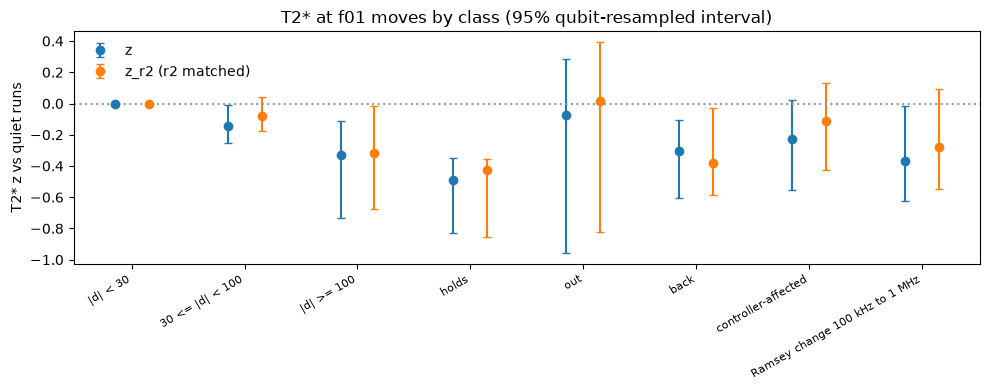

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(assoc))

# z and r2-matched z side by side for each class
series_ = [("dz", "lo", "hi", "z"), ("dz_r2", "lo_r2", "hi_r2", "z_r2 (r2 matched)")]
for off, (c, lo, hi, lab) in zip([-0.15, 0.15], series_):
    v = assoc[c].astype(float)
    err = [v - assoc[lo].astype(float), assoc[hi].astype(float) - v]
    ax.errorbar(x + off, v, yerr=err, fmt="o", capsize=3, label=lab)

ax.axhline(0, color="0.6", ls=":")
ax.set_xticks(x)
ax.set_xticklabels([n.strip() for n in assoc.index], rotation=30, ha="right", fontsize=8)
ax.set(
    ylabel="T2* z vs quiet runs",
    title="T2* at f01 moves by class (95% qubit-resampled interval)",
)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(FIG / "d2a_association.png", dpi=130)
plt.show()

r2 tercile edges of the clean large moves: [0.9948, 0.9969] | quiet runs with a z per tercile: {'low r2': 3643, 'mid r2': 4087, 'high r2': 16205}


runs  qubits     diff     lo     hi
class      r2                                          
|d| >= 100 all        98      16   -0.328 -0.732 -0.114
           low r2     33       7   -0.608  -1.04 -0.308
           mid r2     32       9 -0.00393  -0.46  0.634
           high r2    33      10    0.858  -0.82   4.79
holds      all        40      13    -0.49 -0.826 -0.347
           low r2     15       6   -0.646  -1.03 -0.286
           mid r2     11       6    0.506 -0.355  0.925
           high r2    14       8   -0.427 -0.863   4.38

qubits with >= 5 clean large moves with a z: 4; median per-qubit difference -0.362; below 0 on 3


,large_moves,z_large,z_quiet,diff
qubit,,,,
28,11,-0.537,0.0834,-0.62
4,9,-0.57,0.0477,-0.617
21,51,-0.0633,0.043,-0.106
11,8,0.469,0.0651,0.404


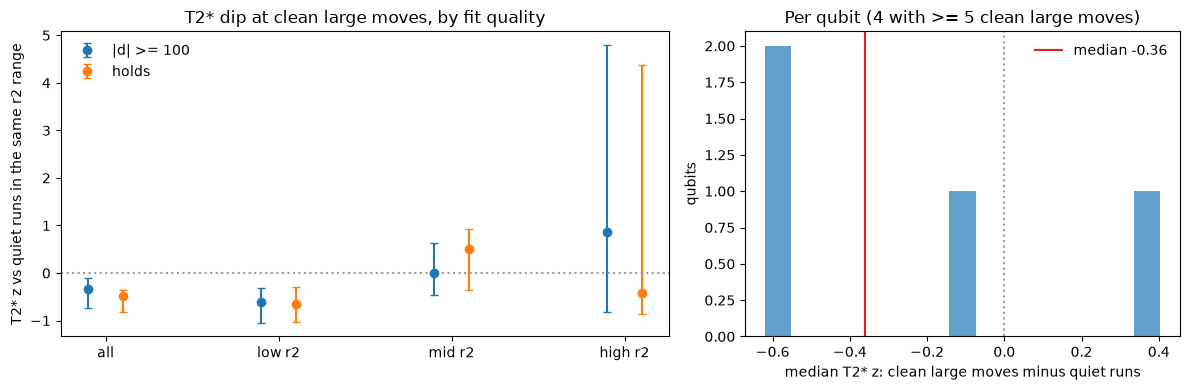

In [9]:
has_z = s["z"].notna()

# r2 terciles of the clean large moves; quiet runs in the same r2 range are the baseline
terciles = s.loc[clean_big & has_z, "r2"].quantile([1 / 3, 2 / 3]).to_numpy()
edges = np.r_[-np.inf, terciles, np.inf]
r2_bin = pd.cut(s["r2"], edges, labels=["low r2", "mid r2", "high r2"])
quiet_per_bin = (base & has_z).groupby(r2_bin, observed=False).sum().to_dict()
print(
    "r2 tercile edges of the clean large moves:",
    np.round(edges[1:-1], 4).tolist(),
    "| quiet runs with a z per tercile:",
    quiet_per_bin,
)

# Dip of all clean large moves and of holds, over all r2 and within each tercile
fitq_classes = [(f"|d| >= {BIG:g}", clean_big), ("holds", classes["  holds"])]
fitq = {}
for name, m in fitq_classes:
    fitq[(name, "all")] = dip(s, m, base, "z")
    for b_ in r2_bin.cat.categories:
        in_bin = r2_bin == b_
        fitq[(name, b_)] = dip(s, m & in_bin, base & in_bin, "z")

fitq = pd.DataFrame(fitq).T
fitq.index.names = ["class", "r2"]
with pd.option_context("display.float_format", "{:.3g}".format):
    display(fitq)

# Per qubit: median z at clean large moves minus median z at quiet runs
large_by_q = s[clean_big & has_z].groupby("qubit")
pq_z = pd.DataFrame(
    {
        "large_moves": large_by_q.size(),
        "z_large": large_by_q["z"].median(),
        "z_quiet": s[base & has_z].groupby("qubit")["z"].median(),
    }
)
pq_z = pq_z[pq_z["large_moves"] >= MIN_QUBIT_MOVES]
pq_z["diff"] = pq_z["z_large"] - pq_z["z_quiet"]
print(
    f"qubits with >= {MIN_QUBIT_MOVES} clean large moves with a z: {len(pq_z)}; "
    f"median per-qubit difference {pq_z['diff'].median():.3g}; "
    f"below 0 on {int((pq_z['diff'] < 0).sum())}"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pq_z.sort_values("diff"))

fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.4, 1]})

# Left: the dip by r2 tercile, for all clean large moves and for holds
ax = axs[0]
bins = ["all"] + list(r2_bin.cat.categories)
x = np.arange(len(bins))
for off, (name, _), c in zip([-0.1, 0.1], fitq_classes, ["C0", "C1"]):
    e = fitq.xs(name, level="class").loc[bins]
    v = e["diff"].astype(float)
    err = [v - e["lo"].astype(float), e["hi"].astype(float) - v]
    ax.errorbar(x + off, v, yerr=err, fmt="o", color=c, capsize=3, label=name)

ax.axhline(0, color="0.6", ls=":")
ax.set_xticks(x)
ax.set_xticklabels(bins)
ax.set(
    ylabel="T2* z vs quiet runs in the same r2 range",
    title="T2* dip at clean large moves, by fit quality",
)
ax.legend(frameon=False)

# Right: the per-qubit differences
ax = axs[1]
ax.hist(pq_z["diff"], bins=15, color="C0", alpha=0.7)
ax.axvline(0, color="0.6", ls=":")
ax.axvline(pq_z["diff"].median(), color="C3", label=f"median {pq_z['diff'].median():.2f}")
ax.set(
    xlabel="median T2* z: clean large moves minus quiet runs",
    ylabel="qubits",
    title=f"Per qubit ({len(pq_z)} with >= {MIN_QUBIT_MOVES} clean large moves)",
)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(FIG / "d2a_t2star_control.png", dpi=130)
plt.show()


**Results.**

- Clean large moves are real changes in the measured f01. 77% of them come with a Ramsey change of 100 kHz or more at the same run, against 34% of controller-affected moves. They also keep a usable T2\* as often as quiet runs (85% against 83%).
- At clean large moves, $z_{r2}$ dips by −0.31 [−0.68, −0.01] (98 runs, 16 qubits). Holds carry most of it (−0.43 [−0.85, −0.35]), and backs dip too (−0.38 [−0.59, −0.03]). Outs (0.02 [−0.82, 0.39]) and controller-affected moves (−0.11 [−0.43, 0.13]) show no clear dip.
- The dip comes with poor fits. In the worst-fit third (r2 below 0.9948) it is −0.61 [−1.04, −0.31] on 33 runs and 7 qubits, and the other two thirds show none. Only 4 qubits have 5 or more clean large moves with a z, and 3 of them dip. Q21 has 51 of the 98 runs but dips by only −0.11.


## 3. Fit or physics? Back to the raw traces

If bad fits cause the dip, the traces at large moves should look different. We refit every large-move trace and a sample of quiet traces with three models:

- **Exponential envelope**, the producer's model. Fast frequency noise gives this shape.
- **Gaussian envelope.** A fixed spread of frequencies across the shots gives this shape, for example slow switching.
- **Two frequencies** with no decay. A TLS that switches within the acquisition gives this.

We report how well the trace sets T2\*, the residuals of the exponential fit, and how often each other model wins. A TLS that switches during the acquisition also lowers r2. So we then compare clean large-move traces in the worst-fit tercile with quiet traces that fit as badly. If a TLS causes the dip, the large-move traces should show more structure.

<details>
<summary><b>Models, fitting and measures</b></summary>

The models are $y(t) = e^{-rt}(a\cos 2\pi f t + b\sin 2\pi f t) + c$ with $T_2^* = 1/r$, the same with $e^{-(rt)^2}$, and $y(t) = \sum_{k=1,2}(a_k\cos 2\pi f_k t + b_k\sin 2\pi f_k t) + c$. With the frequencies and the rate fixed, each model is linear in the rest. So we solve by least squares on a grid over the frequencies and the rate, and keep the point with the smallest residual sum of squares (RSS). We compare models by

$$\text{BIC} = n \ln\frac{\text{RSS}}{n} + k\ln n,$$

with $n = 31$, $k = 5$ for one frequency and $k = 7$ for two.

- **Precision.** Over the 0.5 µs sweep the trace decays by only $1 - e^{-0.5\,\mu\text{s}/T_2^*}$.
- **Residuals.** The rms of the exponential fit and the lag-1 autocorrelation of its residuals. Shape the model misses gives a positive autocorrelation.
- **Shape.** The share where the Gaussian envelope fits better, on traces that decay by at least MIN_DECAY, and the share where two frequencies win by BIC.
- **Worst-fit tercile.** The two groups sit mostly on different qubits, so each is resampled over its own qubits.

</details>


In [10]:
# Rows with a decoded trace; row points into Y
lnk = s[s["row"].notna()].copy()
lnk["row"] = lnk["row"].astype(int)
use = lnk["usable"]

# How well the producer pins T2*: its sd against the value
t2 = lnk.loc[use, "t2star_us"]
rel_sd = (lnk["sd_t2star_us"] / lnk["t2star_us"])[use]
sd_over = (lnk["sd_t2star_us"] > lnk["t2star_us"])[use]
print(
    f"producer T2* (usable rows): median {t2.median():.3g} us; "
    f"median sd/T2* {rel_sd.median():.3g}; "
    f"share with sd > T2* {sd_over.mean():.3g}"
)

# How much the trace decays over the 0.5 us sweep
decay_q = (1 - np.exp(-0.5 / t2)).quantile([0.1, 0.5, 0.9]).round(4).to_dict()
print("decay over the sweep, 1 - exp(-0.5 us / T2*), usable rows, quantiles:", decay_q)

producer T2* (usable rows): median 10.1 us; median sd/T2* 0.701; share with sd > T2* 0.346
decay over the sweep, 1 - exp(-0.5 us / T2*), usable rows, quantiles: {0.1: 0.0127, 0.5: 0.0482, 0.9: 0.2035}


In [11]:
# Envelope shapes on a grid of rates r and delays t
envelopes = {
    "exp": lambda r, t: np.exp(-np.multiply.outer(r, t)),
    "gauss": lambda r, t: np.exp(-(np.multiply.outer(r, t) ** 2)),
}


def fit_one_freq(y, f0, env, chunk=40):
    """Best grid fit of y = E(t)·(a·cos 2πft + b·sin 2πft) + c per trace.

    Returns the RSS, frequency (MHz) and envelope rate of each trace's best grid point.
    """
    E = env(RATES, T_US)  # (rates, delays)
    out = np.empty((len(y), 3))

    for i in range(0, len(y), chunk):
        # Candidate frequencies around each trace's producer frequency
        yy = y[i : i + chunk]
        fq = f0[i : i + chunk, None] + F_OFF

        # Design matrix at every (trace, frequency, rate): damped cos, damped sin, offset
        w = 2 * np.pi * fq[..., None] * T_US
        C = np.cos(w)[:, :, None] * E
        S = np.sin(w)[:, :, None] * E
        X = np.stack([C, S, np.ones_like(C)], -1)

        # Least squares for (a, b, c) at every grid point, through the normal equations
        M = np.einsum("...ti,...tj->...ij", X, X) + 1e-12 * np.eye(3)
        v = np.einsum("cfrti,ct->cfri", X, yy)
        b = np.linalg.solve(M, v[..., None])[..., 0]
        rss = (yy**2).sum(1)[:, None, None] - (b * v).sum(-1)

        # Keep the grid point with the smallest RSS
        flat = rss.reshape(len(yy), -1)
        k = flat.argmin(1)
        jf, jr = np.unravel_index(k, rss.shape[1:])
        idx = np.arange(len(yy))
        out[i : i + chunk] = np.c_[flat[idx, k], fq[idx, jf], RATES[jr]]

    return out


# All frequency pairs on the two-frequency grid at least MIN_SPLIT apart
iu, ju = np.triu_indices(len(F2_OFF), 1)
keep = (F2_OFF[ju] - F2_OFF[iu]) >= MIN_SPLIT
iu, ju = iu[keep], ju[keep]


def fit_two_freq(y, f0, chunk=8):
    """Best grid fit of two undamped cosines plus an offset per trace.

    Returns the RSS and the two frequencies (MHz) of each trace's best pair.
    """
    out = np.empty((len(y), 3))

    for i in range(0, len(y), chunk):
        yy = y[i : i + chunk]
        fq = f0[i : i + chunk, None] + F2_OFF

        # Design matrix at every (trace, pair): cos and sin of each frequency, offset
        w = 2 * np.pi * fq[..., None] * T_US
        C, S = np.cos(w), np.sin(w)
        ones = np.ones((len(yy), len(iu), len(T_US)))
        X = np.stack([C[:, iu], S[:, iu], C[:, ju], S[:, ju], ones], -1)

        # Least squares for the five amplitudes at every pair
        M = np.einsum("cpti,cptj->cpij", X, X) + 1e-12 * np.eye(5)
        v = np.einsum("cpti,ct->cpi", X, yy)
        b = np.linalg.solve(M, v[..., None])[..., 0]
        rss = (yy**2).sum(1)[:, None] - (b * v).sum(-1)

        # Keep the pair with the smallest RSS
        k = rss.argmin(1)
        idx = np.arange(len(yy))
        out[i : i + chunk] = np.c_[rss[idx, k], fq[idx, iu[k]], fq[idx, ju[k]]]

    return out


def basis(fit: np.ndarray, j: int, env, t: np.ndarray) -> np.ndarray:
    """Damped cos, damped sin and offset at trace j's best grid point (one-frequency fits)."""
    e_ = env(fit[j, 2], t)
    w = 2 * np.pi * fit[j, 1] * t
    return np.c_[np.cos(w) * e_, np.sin(w) * e_, np.ones(len(t))]


def bic(rss, k: int, n: int = len(T_US)):
    """BIC of a least-squares fit with k parameters on n points."""
    return n * np.log(rss / n) + k * np.log(n)

In [12]:
t0 = time.time()

# Every large move with a trace, plus N_BASE_FIT random quiet runs
large_rows = lnk[lnk["size"] == f">={BIG:g}"]
quiet_rows = lnk[lnk["quiet"]]
quiet_sample = quiet_rows.sample(min(N_BASE_FIT, len(quiet_rows)), random_state=0)
pick = pd.concat([large_rows, quiet_sample])
pick["cls"] = np.select(
    [pick["quiet"], pick["ctrl"]], ["quiet", "controller-affected"], "large " + pick["kind"]
)


def lag1(e: np.ndarray) -> float:
    """Lag-1 autocorrelation of a residual."""
    return np.corrcoef(e[:-1], e[1:])[0, 1]


def refit(rows: pd.DataFrame):
    """Refit each row's Ramsey trace with the three models.

    Returns the rows with the shape columns added, and the exponential and Gaussian grid fits
    (for plotting).
    """
    Yx = Y[rows["row"].to_numpy()]
    f0 = rows["f_hz"].to_numpy() / 1e6  # MHz: the producer's frequency centres the grid

    # The three grid fits
    fe = fit_one_freq(Yx, f0, envelopes["exp"])
    fg = fit_one_freq(Yx, f0, envelopes["gauss"])
    f2 = fit_two_freq(Yx, f0)

    # Residual rms and decay over the sweep of the exponential fit
    out = rows.copy()
    n = len(T_US)
    r_exp = fe[:, 2]
    out["rms_exp"] = np.sqrt(fe[:, 0] / (n - 5))
    out["decay_exp"] = 1 - np.exp(-r_exp * T_US[-1])

    # Refitted T2* = 1 / rate; a rate of 0 means no decay
    safe_rate = np.where(r_exp > 0, r_exp, 1)
    out["t2_refit_us"] = np.where(r_exp > 0, 1 / safe_rate, np.inf)

    # Which shape wins, and the two-frequency split
    out["gauss_better"] = fg[:, 0] < fe[:, 0]
    out["two_freq_wins"] = bic(f2[:, 0], 7) < bic(fe[:, 0], 5)
    out["split_khz"] = (f2[:, 2] - f2[:, 1]) * 1e3

    # Residual of each trace at its best exponential-envelope grid point
    resid_lag1 = []
    for j in range(len(out)):
        X = basis(fe, j, envelopes["exp"], T_US)
        e = Yx[j] - X @ np.linalg.lstsq(X, Yx[j], rcond=None)[0]
        resid_lag1.append(lag1(e))
    out["resid_lag1"] = resid_lag1

    return out, fe, fg


pick, fe, fg = refit(pick)
is_cl = pick["cls"].str.startswith("large ")  # clean large moves
print(f"refitted {len(pick)} traces in {time.time() - t0:.0f} s")

# Summary per class; the envelope shape only on traces that decay enough to show it
dec_ok = pick["decay_exp"] >= MIN_DECAY
tab = pick.groupby("cls").agg(
    traces=("row", "size"),
    qubits=("qubit", "nunique"),
    usable=("usable", "mean"),
    median_r2=("r2", "median"),
    median_rms_exp=("rms_exp", "median"),
    median_resid_lag1=("resid_lag1", "median"),
    median_decay=("decay_exp", "median"),
    two_freq_wins=("two_freq_wins", "mean"),
)
tab["decaying"] = pick[dec_ok].groupby("cls").size()
tab["gauss_better_if_decaying"] = pick[dec_ok].groupby("cls")["gauss_better"].mean()
tab["median_split_khz_if_two"] = pick[pick["two_freq_wins"]].groupby("cls")["split_khz"].median()
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tab)

# Usable traces only: residual rms and two-frequency wins, quiet against clean large
uu = pick[pick["usable"]]
q_u, l_u = uu[uu["quiet"]], uu[is_cl[pick["usable"]]]
print(
    f"usable traces only: median rms_exp quiet {q_u['rms_exp'].median():.4f}, "
    f"clean large {l_u['rms_exp'].median():.4f}; "
    f"two-frequency wins quiet {q_u['two_freq_wins'].mean():.3g}, "
    f"clean large {l_u['two_freq_wins'].mean():.3g}"
)

# Refitted against producer T2*, where the refit is finite and the row usable
both_fin = np.isfinite(pick["t2_refit_us"]) & pick["usable"] & (pick["t2_refit_us"] < T2_MAX_US)
ratio = pick.loc[both_fin, "t2_refit_us"] / pick.loc[both_fin, "t2star_us"]
print(
    f"refit vs producer T2* (usable, finite): median ratio {ratio.median():.3g} "
    f"on {int(both_fin.sum())} traces"
)

# Does the two-frequency split grow with the move?
lg = pick[is_cl & pick["two_freq_wins"]]
split_corr = lg["split_khz"].rank().corr(lg["d"].abs().rank())
print(
    f"clean large moves where two frequencies win: {len(lg)}; "
    f"Spearman rank corr of split with |d|: {split_corr:.3g}"
)


refitted 2842 traces in 130 s


,traces,qubits,usable,median_r2,median_rms_exp,median_resid_lag1,median_decay,two_freq_wins,decaying,gauss_better_if_decaying,median_split_khz_if_two
cls,,,,,,,,,,,
controller-affected,705,22,0.759,0.976,0.105,0.173,0.139,0.163,357,0.261,1.37e+03
large back,26,9,0.885,0.996,0.0486,-3.42e-05,0.117,0.385,13,0.923,662
large holds,72,15,0.792,0.994,0.0516,-0.0178,0.0952,0.153,34,0.588,775
large out,39,9,0.949,0.996,0.0454,0.0522,0.181,0.462,27,0.63,762
quiet,2000,30,0.835,0.998,0.0358,-0.0172,0.0488,0.131,331,0.42,1.27e+03


usable traces only: median rms_exp quiet 0.0357, clean large 0.0452; two-frequency wins quiet 0.128, clean large 0.316
refit vs producer T2* (usable, finite): median ratio 0.976 on 1864 traces
clean large moves where two frequencies win: 39; Spearman rank corr of split with |d|: -0.112


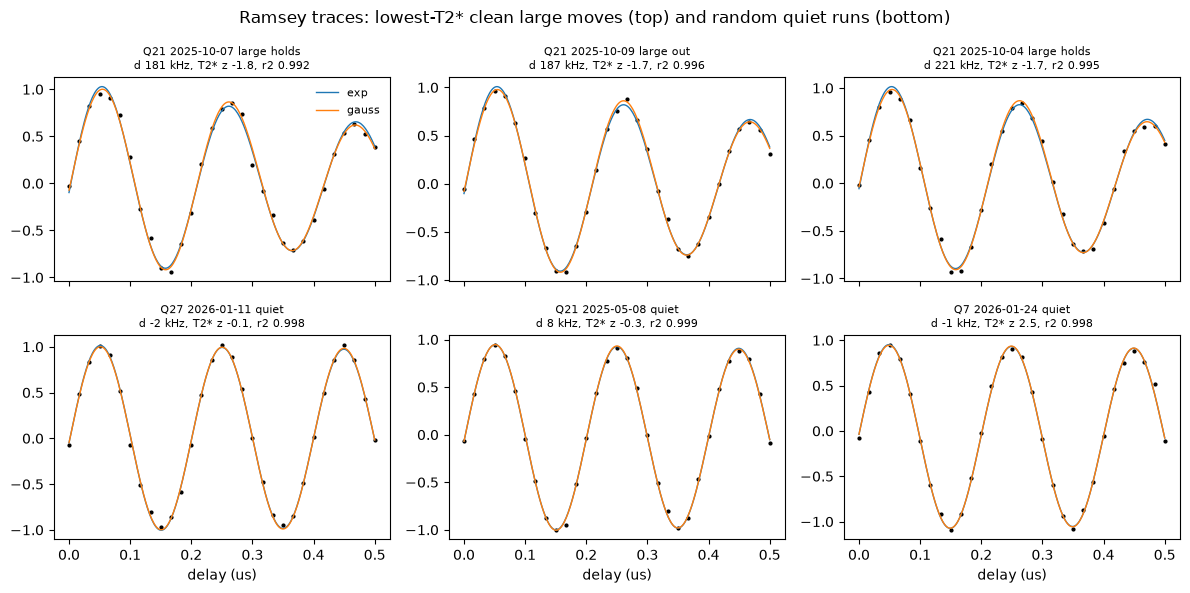

In [13]:
# The three lowest-T2* clean large moves against three random quiet runs
low_large = pick[is_cl & pick["z"].notna()].nsmallest(3, "z")
some_quiet = pick[pick["quiet"] & pick["z"].notna()].sample(3, random_state=1)
ex = pd.concat([low_large, some_quiet])

fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
tt = np.linspace(0, 0.5, 300)  # fine delay grid for the fitted curves (us)

for a, (_, r) in zip(axs.ravel(), ex.iterrows()):
    # The measured trace
    y = Y[r["row"]]
    a.plot(T_US, y, "k.", ms=4)

    # The exponential and Gaussian fits at this trace's best grid point
    j = pick.index.get_loc(r.name)
    for lab, fit in [("exp", fe), ("gauss", fg)]:
        env = envelopes[lab]
        coef = np.linalg.lstsq(basis(fit, j, env, T_US), y, rcond=None)[0]
        a.plot(tt, basis(fit, j, env, tt) @ coef, lw=1, label=lab)

    a.set_title(
        f"Q{r['qubit']} {r['t']:%Y-%m-%d} {r['cls']}\n"
        f"d {r['d']:.0f} kHz, T2* z {r['z']:.1f}, r2 {r['r2']:.3f}",
        fontsize=8,
    )

axs[0, 0].legend(frameon=False, fontsize=8)
for a in axs[1]:
    a.set_xlabel("delay (us)")

fig.suptitle("Ramsey traces: lowest-T2* clean large moves (top) and random quiet runs (bottom)")
fig.tight_layout()
fig.savefig(FIG / "d2a_traces.png", dpi=130)
plt.show()


In [14]:
# The worst-fit tercile from section 2: clean large moves (already refitted) against every quiet
# run that fits as badly
low = lnk["z"].notna() & (lnk["r2"] < terciles[0])
low_quiet, _, _ = refit(lnk[low & lnk["quiet"]])
low_large = pick[is_cl & pick["row"].isin(lnk.loc[low, "row"])]
both = pd.concat([low_large, low_quiet.assign(cls="quiet")])
print(
    f"r2 below {terciles[0]:.4f}: "
    f"{len(low_large)} clean large moves on {low_large['qubit'].nunique()} qubits, "
    f"{len(low_quiet)} quiet runs on {low_quiet['qubit'].nunique()} qubits"
)

# Summary per class, as for the full refit
dec = both["decay_exp"] >= MIN_DECAY
low_tab = both.groupby("cls").agg(
    traces=("row", "size"),
    qubits=("qubit", "nunique"),
    median_r2=("r2", "median"),
    median_rms_exp=("rms_exp", "median"),
    median_resid_lag1=("resid_lag1", "median"),
    median_decay=("decay_exp", "median"),
    two_freq_wins=("two_freq_wins", "mean"),
)
low_tab["gauss_better_if_decaying"] = both[dec].groupby("cls")["gauss_better"].mean()
with pd.option_context("display.float_format", "{:.3g}".format):
    display(low_tab)


def group_diff(
    d: pd.DataFrame, mask: pd.Series, base: pd.Series, col: str, stat=np.median, seed: int = 0
) -> dict:
    """stat of col in the masked rows minus stat in the base rows, with a 95% interval.

    The two groups sit largely on different qubits here, so each is resampled over its own
    qubits (unlike dip()).
    """
    a = d[mask & d[col].notna()]
    b = d[base & d[col].notna()]

    # Values per qubit in each group
    ga = {q: v.to_numpy(float) for q, v in a.groupby("qubit")[col]}
    gb = {q: v.to_numpy(float) for q, v in b.groupby("qubit")[col]}
    qa, qb = np.array(list(ga)), np.array(list(gb))

    # Resample each group's qubits on their own
    r = np.random.default_rng(seed)
    boot = np.empty(N_BOOT)
    for i in range(N_BOOT):
        in_class = np.concatenate([ga[q] for q in r.choice(qa, len(qa))])
        in_base = np.concatenate([gb[q] for q in r.choice(qb, len(qb))])
        boot[i] = stat(in_class) - stat(in_base)

    return {
        "runs": len(a),
        "base_runs": len(b),
        "diff": stat(a[col].to_numpy(float)) - stat(b[col].to_numpy(float)),
        "lo": np.percentile(boot, 2.5),
        "hi": np.percentile(boot, 97.5),
    }


# Clean large minus quiet within the tercile, for each trace-shape measure
is_large, is_quiet = both["cls"] != "quiet", both["cls"] == "quiet"
low_cmp = pd.DataFrame(
    {
        "resid lag-1 (median)": group_diff(both, is_large, is_quiet, "resid_lag1"),
        "rms_exp (median)": group_diff(both, is_large, is_quiet, "rms_exp"),
        "two frequencies win (share)": group_diff(
            both, is_large, is_quiet, "two_freq_wins", np.mean
        ),
        "Gaussian better, decaying (share)": group_diff(
            both, is_large & dec, is_quiet & dec, "gauss_better", np.mean
        ),
    }
).T
print("clean large moves minus quiet runs, both with r2 in the worst-fit tercile:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(low_cmp)


r2 below 0.9948: 33 clean large moves on 7 qubits, 3643 quiet runs on 30 qubits


,traces,qubits,median_r2,median_rms_exp,median_resid_lag1,median_decay,two_freq_wins,gauss_better_if_decaying
cls,,,,,,,,
large back,7,2,0.994,0.0505,0.309,0.423,0.857,0.857
large holds,15,6,0.992,0.0663,0.199,0.33,0.333,0.571
large out,11,5,0.982,0.0566,0.289,0.295,0.455,0.4
quiet,3643,30,0.991,0.0665,0.172,0.0952,0.111,0.323


clean large moves minus quiet runs, both with r2 in the worst-fit tercile:


,runs,base_runs,diff,lo,hi
resid lag-1 (median),33,3.64e+03,0.0801,0.00927,0.167
rms_exp (median),33,3.64e+03,-0.00991,-0.0181,0.0446
two frequencies win (share),33,3.64e+03,0.374,-0.102,0.696
"Gaussian better, decaying (share)",31,1.56e+03,0.258,-0.25,0.552


**Results.**

- The fit has little data to set T2\*. The median trace decays by 4.8% over the sweep, and 35% of fits have an sd larger than T2\* itself. Our refit agrees with the producer (median ratio 0.98).
- Clean large-move traces fit a little worse than quiet ones (median rms 0.045 against 0.036 on usable traces). Two frequencies win more often at outs (46%) and backs (39%) than at holds (15%) or quiet runs (13%), and the split doesn't grow with $|d|$ (rank correlation −0.11). Controller-affected traces fit worst (rms 0.105).
- In the worst-fit third, clean large-move traces have more correlated residuals than quiet traces that fit as badly (+0.08 [0.01, 0.17]). They also win more often with two frequencies or a Gaussian envelope, but both intervals include 0.


## 4. A second measurement: FineFrequency contrast

The FineFrequency ladder runs a few minutes after the Ramsey, in the same run. Each step uses one delay $\tau$ (0.1, 0.25, then 0.5 µs) and fits a line to the fringe near its centre. The slope gives the fringe contrast $C(\tau)$, and the ratio

$$\rho = \frac{C(0.25\,\mu\text{s})}{C(0.1\,\mu\text{s})}$$

measures the decay without the Ramsey fit. $\rho_5 = C(0.5)/C(0.1)$ spans a longer delay. $\rho_c$ and $\rho_{5,c}$ divide out the centre offset. We use a robust z of each log ratio per qubit and segment.

We ask three questions:

- **Does it agree with Ramsey?** The rank correlation with T2\* z on quiet runs, then the dip at large moves.
- **Does the centre offset explain the dip?** If it does, $\rho_c$ shows no dip.
- **Does low T2\* make the ladder fail?** If the warned share rises as T2\* z falls, a warning follows from the dip rather than causing it.

<details>
<summary><b>Contrast, decay time and centre offset</b></summary>

Near the centre the fringe is

$$P(\delta) \approx B \pm C\sin(2\pi\delta\tau) \approx B \pm 2\pi\tau C\,\delta,$$

so $C = |\text{slope}| / 2\pi\tau$. If $C(\tau) = C_0 e^{-\tau/T}$, then $\rho = e^{-0.15\,\mu\text{s}/T}$, and the readout scale $C_0$ cancels.

The sweep is centred on the step's starting frequency, not on the fringe. If the lines cross at an offset $\delta_0$, the slope is $\cos(2\pi\delta_0\tau)$ times the slope at the fringe, so an off-centre step reads a lower contrast. $\delta_0$ is the step's own correction, so we divide it out, $C_c = C / \cos(2\pi\delta_0\tau)$, where the factor is at least COS_MIN.

$\rho$ needs the 0.25 µs step accepted, and $\rho_5$ the 0.5 µs step. The ladder has the 0.5 µs step from FINE_LADDER_05 on, except during FINE_LADDER_05_OFF (d2b, section 8).

</details>


In [15]:
t0 = time.time()

# FineFrequency claims from the run map, with their local payloads
fc = claims("freq")
print(
    f"FineFrequency claims {len(fc)}, local {int(fc['path'].notna().sum())}, "
    f"files {fc['path'].nunique()}"
)

# Per payload and qubit: the step's delay, the fringe contrast and the centre offset
con = {}
for path in fc["path"].dropna().unique():
    try:
        obj = decode.payload(path)
    except decode.PayloadError:
        continue

    # The step's delay (us), and each target's frequency at the sweep centre
    cfg = decode.plain(obj["dict"]["config"])
    tau = round(float(cfg["delay"]) * 1e6, 3)

    for target, entry in decode.iter_targets(obj):
        # One line fit per phase; keep the slope magnitudes
        try:
            slopes = [abs(decode.fit_vector(fit).value("A_1")) for fit in entry["fits"]]
        except (KeyError, TypeError, ValueError):
            continue

        # The step's new frequency minus the sweep centre is where the two lines cross (Hz)
        try:
            new_hz = float(decode.plain(entry["new_frequency"]))
            offset = new_hz - float(cfg["old_frequencies"][target])
        except (KeyError, TypeError, ValueError):
            offset = np.nan

        # C = |slope| / (2 pi tau)
        con[(path, target)] = (tau, np.mean(slopes) / (2 * np.pi * tau * 1e-6), offset)

# Back onto the claims
cn = pd.DataFrame.from_dict(con, orient="index", columns=["tau_us", "contrast", "offset_hz"])
cn.index = pd.MultiIndex.from_tuples(cn.index, names=["path", "key"])
ff = fc.join(cn, on=["path", "key"], how="inner")

delay_counts = ff["tau_us"].value_counts().sort_index().to_dict()
print(f"decoded {len(cn)} target fits in {time.time() - t0:.0f} s; delays {delay_counts}")
print("median contrast by delay:", ff.groupby("tau_us")["contrast"].median().round(3).to_dict())

# An offset scales the slope by cos(2 pi offset tau); divide it out where that's COS_MIN or more
cos_f = np.cos(2 * np.pi * ff["offset_hz"] * ff["tau_us"] * 1e-6)
ff["contrast_c"] = (ff["contrast"] / cos_f).where(cos_f >= COS_MIN)
cos_q = ff.groupby("tau_us")["offset_hz"].apply(
    lambda v: np.cos(2 * np.pi * v * v.name * 1e-6).quantile([0.01, 0.1, 0.5]).round(4).to_dict()
)
print("cos factor quantiles (1%, 10%, 50%) by delay:", cos_q.unstack().to_dict("index"))
print(f"share of fits with cos factor below {COS_MIN}: {(cos_f < COS_MIN).mean():.3g}")

# Contrast per run and qubit, one column per delay: as measured, and with the offset divided out
cp = ff.pivot_table(index=["start", "qubit"], columns="tau_us", values="contrast", aggfunc="first")
cpc = ff.pivot_table(index=["start", "qubit"], columns="tau_us", values="contrast_c", aggfunc="first")


def add_ratio(
    s: pd.DataFrame, col: str, tau: float, table: pd.DataFrame
) -> tuple[pd.DataFrame, pd.Series]:
    """Join C(tau) / C(0.1 us) from table to s as col, with its robust z (of the log) per qubit
    and segment."""
    ratio = (table[tau] / table[FF_DELAYS[0]]).rename(col)

    # Replace any earlier copy of the two columns
    s = s.drop(columns=[c for c in [col, col + "_z"] if c in s])
    s = s.join(ratio, on=["t", "qubit"])

    # Robust z of the log ratio, where the ratio is positive
    ok = s[col] > 0
    logs = s[ok].assign(l=np.log(s.loc[ok, col]))
    s.loc[ok, col + "_z"] = logs.groupby(["qubit", "seg"])["l"].transform(robust_z)
    return s, ok


def contrast_dips(col: str) -> pd.DataFrame:
    """Dip of col's z against quiet runs, for the large-move classes."""
    out = {}
    for name in [f"|d| >= {BIG:g}", "  holds", "  out", "  back", "controller-affected"]:
        m = classes[name]
        d_ = dip(s, m, base, col + "_z")
        out[name] = {
            f"with {col}": int((m & s[col + "_z"].notna()).sum()),
            f"share of class with {col}": (m & s[col].notna()).sum() / m.sum(),
            "qubits": d_["qubits"],
            "diff": d_["diff"],
            "lo": d_["lo"],
            "hi": d_["hi"],
        }
    return pd.DataFrame(out).T


# rho = C(0.25 us) / C(0.1 us), and the decay time it implies; rho_c with the offsets divided out
s, ok = add_ratio(s, "rho", FF_DELAYS[1], cp)
s, ok_c = add_ratio(s, "rho_c", FF_DELAYS[1], cpc)
rho_med = s.loc[ok, "rho"].median()
print(
    f"rows with rho {int(ok.sum())}, with rho z {int(s['rho_z'].notna().sum())}; "
    f"median rho {rho_med:.4f} "
    f"(implied decay time over 0.1 to 0.25 us: {0.15 / -np.log(rho_med):.3g} us)"
)
print(f"rows with rho_c {int(ok_c.sum())}, with rho_c z {int(s['rho_c_z'].notna().sum())}")

# How much the offsets lower log rho, on quiet runs and at clean large moves
off_part = np.log(s["rho"] / s["rho_c"])
print(
    "median log(rho / rho_c): "
    f"quiet {off_part[base].median():.3g}, clean |d| >= {BIG:g} {off_part[clean_big].median():.3g}"
)

# Does it agree with Ramsey on quiet runs?
for col in ["rho", "rho_c"]:
    q_ = s[s["quiet"]].dropna(subset=["z", col + "_z"])
    rho_corr = q_["z"].rank().corr(q_[col + "_z"].rank())
    print(f"quiet runs: Spearman corr of T2* z and {col} z {rho_corr:.3g} on {len(q_)} runs")

# The dip at large moves, as measured and with the offsets divided out
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.concat({"rho": contrast_dips("rho"), "rho_c": contrast_dips("rho_c")}, axis=1))


FineFrequency claims 99304, local 99304, files 6951
decoded 101252 target fits in 8 s; delays {0.1: 35949, 0.25: 35110, 0.5: 28245}
median contrast by delay: {0.1: 0.977, 0.25: 0.964, 0.5: 0.943}
cos factor quantiles (1%, 10%, 50%) by delay: {0.1: {0.01: 0.9801, 0.1: 0.9979, 0.5: 0.9997}, 0.25: {0.01: 0.9714, 0.1: 0.9927, 0.5: 0.9992}, 0.5: {0.01: 0.9799, 0.1: 0.9967, 0.5: 0.9997}}
share of fits with cos factor below 0.95: 0
rows with rho 34477, with rho z 33347; median rho 0.9841 (implied decay time over 0.1 to 0.25 us: 9.35 us)
rows with rho_c 34477, with rho_c z 33347
median log(rho / rho_c): quiet -0.000482, clean |d| >= 100 -0.000385
quiet runs: Spearman corr of T2* z and rho z 0.039 on 23912 runs
quiet runs: Spearman corr of T2* z and rho_c z 0.0381 on 23912 runs


rho                                                           rho_c                                                       
                    with rho share of class with rho qubits   diff     lo      hi with rho_c share of class with rho_c qubits   diff     lo      hi
|d| >= 100               119                   0.926     17 -0.226 -0.371  0.0153        119                     0.926     17 -0.221 -0.396  0.0217
  holds                   56                   0.923     15 -0.373  -0.69 -0.0552         56                     0.923     15 -0.388 -0.718  -0.103
  out                     38                   0.929      8 -0.187 -0.755    0.11         38                     0.929      8 -0.235 -0.767  0.0808
  back                    25                   0.929      9  0.184 -0.267   0.632         25                     0.929      9  0.113 -0.241   0.605
controller-affected      237                   0.371     19  -0.39 -0.641  -0.172        237                     0.371     19 -0.319 -0.635 -0.0811

In [16]:
# rho5 = C(0.5 us) / C(0.1 us), and the decay time it implies; rho5_c with the offsets divided out
s, ok5 = add_ratio(s, "rho5", FF_DELAYS[2], cp)
s, ok5_c = add_ratio(s, "rho5_c", FF_DELAYS[2], cpc)
rho5_med = s.loc[ok5, "rho5"].median()
print(
    f"rows with rho5 {int(ok5.sum())}, with rho5 z {int(s['rho5_z'].notna().sum())}; "
    f"median rho5 {rho5_med:.4f} "
    f"(implied decay time over 0.1 to 0.5 us: {0.4 / -np.log(rho5_med):.3g} us)"
)
print(f"rows with rho5_c {int(ok5_c.sum())}, with rho5_c z {int(s['rho5_c_z'].notna().sum())}")

# Agreement with T2* z and with rho z on quiet runs
q5 = s[s["quiet"]]
for col, other in [("rho5", "z"), ("rho5", "rho_z"), ("rho5_c", "z"), ("rho5_c", "rho_c_z")]:
    pr = q5.dropna(subset=[col + "_z", other])
    pr_corr = pr[col + "_z"].rank().corr(pr[other].rank())
    print(f"quiet runs: Spearman corr of {col} z and {other} {pr_corr:.3g} on {len(pr)} runs")

# The dip at large moves, as measured and with the offsets divided out
with pd.option_context("display.float_format", "{:.3g}".format):
    display(
        pd.concat({"rho5": contrast_dips("rho5"), "rho5_c": contrast_dips("rho5_c")}, axis=1)
    )


rows with rho5 27665, with rho5 z 27386; median rho5 0.9636 (implied decay time over 0.1 to 0.5 us: 10.8 us)
rows with rho5_c 27665, with rho5_c z 27386
quiet runs: Spearman corr of rho5 z and z 0.103 on 19595 runs
quiet runs: Spearman corr of rho5 z and rho_z 0.417 on 23848 runs
quiet runs: Spearman corr of rho5_c z and z 0.102 on 19595 runs
quiet runs: Spearman corr of rho5_c z and rho_c_z 0.418 on 23848 runs


rho5                                                              rho5_c                                                         
                    with rho5 share of class with rho5 qubits     diff     lo      hi with rho5_c share of class with rho5_c qubits     diff     lo     hi
|d| >= 100                116                    0.824     15  -0.0276 -0.352    0.13         116                      0.824     15  -0.0189 -0.356  0.126
  holds                    55                    0.782     14  -0.0337 -0.288   0.102          55                      0.782     14  -0.0542 -0.309  0.138
  out                      37                    0.881      7 -0.00914  -1.26   0.225          37                      0.881      7 -0.00897  -1.23  0.223
  back                     24                    0.857      8    0.146  -0.96   0.774          24                      0.857      8    0.101  -0.94  0.747
controller-affected       154                    0.242     17   -0.429 -0.707 -0.0632         154                      0.242     17   -0.399 -0.759 -0.148

In [17]:
# T2* z bands
band_edges = [-np.inf, -2, -1, 1, np.inf]
band_labels = ["z < -2", "-2 to -1", "-1 to 1", "z > 1"]
band = pd.cut(s["z"], band_edges, labels=band_labels)

# Warned share and run count by T2* z band, within each size class
has_size = s["z"].notna() & (s["size"] != "")
wt = s[has_size].pivot_table(
    index="size", columns=band, values="warned", aggfunc=["mean", "size"], observed=False
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(wt)

mean                           size                       
z      z < -2 -2 to -1 -1 to 1  z > 1 z < -2 -2 to -1 -1 to 1 z > 1
size                                                               
30-100    0.5    0.222   0.271   0.29      4      117     949   324
<30         0   0.0269  0.0188 0.0193     24     1116   18043  7041
>=100   0.667    0.688   0.575  0.374      3       80     369   147

**Results.**

- 101,252 target fits decode. Every fit has a cos factor of 0.95 or more, so the offset correction changes little.
- 34,477 rows have a $\rho$, with a median of 0.984 (a decay time of 9.4 µs). On quiet runs $z_\rho$ barely follows T2\* z (rank correlation 0.04), and $z_{\rho_5}$ follows $z_\rho$ (0.42) more than T2\* z (0.10).
- Clean holds dip in $\rho_c$ by −0.39 [−0.72, −0.10]. All clean large moves give −0.22 [−0.40, 0.02], and $\rho_5$ shows no dip at any clean class. Controller-affected moves dip in both ($z_{\rho_c}$ −0.32 [−0.64, −0.08], $z_{\rho_{5,c}}$ −0.40 [−0.76, −0.15]), but only 37% of them reach the 0.25 µs step.
- Among large moves the warned share rises as T2\* falls: 37% above z = 1, 58% between −1 and 1, and 69% between −2 and −1. Among small changes it stays at about 2%.


## 5. Which coherence drops: T1, T2echo and the infidelities

The KPIs separate loss from dephasing. Frequency switching adds only dephasing, which the echo mostly removes, so it predicts no change in T1 and little in T2echo. Loss lowers T1 and T2echo and raises the 1q RB and readout infidelities (fRB, fRO). The 2q infidelity (fCX) measures cost, since a 2q gate detunes whenever f01 moves.

For each calibrate_1q run we take the qubit's KPI from the last benchmarking run before it and the first after it, within KPI_TOL. We compare

$$\Delta\log_{10}x = \log_{10}x_{\text{after}} - \log_{10}x_{\text{before}}$$

in each class with quiet runs, on the KPI rows that B4 keeps (`series.kept_kpi`).

**Censoring.** The gate drops failed fits. If a coherence drop makes the after fit fail, the drop never shows as a $\Delta$. So we also compare the share of censored after KPIs in each class with quiet runs.

<details>
<summary><b>Matching rules</b></summary>

- **After KPI.** It must come before the qubit's next calibrate_1q run, or it measures the state a later run set. This keeps about half the runs. The before KPI has no such rule, because requiring both leaves almost no runs.
- **Couplings.** A coupling's fCX counts for both of its qubits, and each run takes the median over the qubit's couplings.
- **Censoring.** For T1, T2, fRB and fRO we take the first attempted after KPI, with the same window and rule, and skip era-0 fits that the gate can't judge. Each group is resampled over its own qubits, as in section 3.

</details>


In [18]:
# Kept rows of the five DS3 KPIs
METRICS = ["T1", "T2", "fRB", "fRO", "fCX"]
kpi_all = series.kpi_rows(load_kpi_l2(path=KPI_SUPPLEMENTED_PATH), load_runs_l2())
kpi = series.kept_kpi(kpi_all)
kpi = kpi[kpi["metric"].isin(METRICS)]
kpi = kpi.assign(t=kpi["t"].astype("datetime64[ns]"))
print("kept KPI rows:", kpi.groupby("metric").size().to_dict())

# A qubit KPI belongs to its qubit; a coupling KPI (fCX, element "a-b") belongs to both qubits
on_qubit = kpi[kpi["element_type"] == "qubit"].assign(qubit=lambda d: d["element"].astype(int))
coupl = kpi[kpi["element_type"] == "coupling"]
ends = coupl["element"].str.split("-", expand=True).astype(int)
kpi = pd.concat([on_qubit, coupl.assign(qubit=ends[0]), coupl.assign(qubit=ends[1])])

# The qubit's next calibrate_1q run, from all its runs (incidents and settling included)
f_sorted = f.sort_values(["qubit", "t"])
next_run = f_sorted.groupby("qubit")["t"].shift(-1)
next_run.index = pd.MultiIndex.from_frame(f_sorted[["qubit", "t"]])
next_run = next_run.groupby(level=[0, 1]).first()
t_next = next_run.reindex(pd.MultiIndex.from_frame(s[["qubit", "t"]])).to_numpy()

# KPI change around each calibrate_1q run, per metric
left = s[["qubit", "t"]].assign(
    t=s["t"].astype("datetime64[ns]"), t_next=pd.to_datetime(t_next).astype("datetime64[ns]")
)
left = left.reset_index()
kpi_pairs = {}
for metric in METRICS:
    k_ = kpi.loc[kpi["metric"] == metric, ["qubit", "element", "t", "lx"]].sort_values("t")
    k_ = k_.assign(t_kpi=k_["t"])

    # One row per run and element: the qubit itself, or each coupling it is part of
    l_ = left.merge(k_[["qubit", "element"]].drop_duplicates(), on="qubit").sort_values("t")

    # The last KPI strictly before the run and the first at or after it
    by = ["qubit", "element"]
    before = pd.merge_asof(
        l_, k_, on="t", by=by, direction="backward", tolerance=KPI_TOL, allow_exact_matches=False
    )
    after = pd.merge_asof(l_, k_, on="t", by=by, direction="forward", tolerance=KPI_TOL)

    # The after KPI must come before the qubit's next run, so it measures the state this run set
    in_state = after["t_kpi"] < after["t_next"]
    has_both = before["lx"].notna() & after["lx"].notna()
    kpi_pairs[metric] = {
        "pairs": int(has_both.sum()),
        "after KPI before the next run": int((has_both & in_state).sum()),
    }

    # After minus before, as a median over a qubit's couplings
    change = (after["lx"].where(in_state) - before["lx"]).groupby(before["index"]).median()
    s["d_" + metric] = change.reindex(s.index)

print("run and element pairs with a KPI before and after:")
display(pd.DataFrame(kpi_pairs).T)

# Dip in each KPI change against quiet runs, per move class
kt_classes = [
    f"|d| < {SMALL:g}",
    f"{SMALL:g} <= |d| < {BIG:g}",
    f"|d| >= {BIG:g}",
    "  holds",
    "  out",
    "  back",
    "controller-affected",
]
kt = {}
for name in kt_classes:
    for metric in METRICS:
        kt[(name, metric)] = dip(s, classes[name], base, "d_" + metric)
kt = pd.DataFrame(kt).T
kt.index.names = ["class", "metric"]

# The quiet baseline: how many runs have a change, and its median
n_quiet = {m_: int((base & s["d_" + m_].notna()).sum()) for m_ in METRICS}
med_quiet = {m_: round(float(s.loc[base, "d_" + m_].median()), 4) for m_ in METRICS}
print("quiet runs with a KPI change:", n_quiet, "| quiet median change:", med_quiet)

# One column block per metric
kt_wide = kt.unstack("metric").swaplevel(0, 1, axis=1).sort_index(axis=1)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(kt_wide)

# Censoring: the first attempted qubit KPI after each run (ok or censored), with the same window
# and next-run rule; skip incidents, f01 flags and era-0 fits, which the gate can't judge
era0_fit = (kpi_all["gating_regime"] == "era0_ungated") & (kpi_all["metric"] != "fRO")
att = kpi_all[
    kpi_all["metric"].isin(CENSOR_METRICS)
    & (kpi_all["element_type"] == "qubit")
    & (kpi_all["cls"] != "absent")
    & ~kpi_all["incident"]
    & ~kpi_all["f01_flag"]
    & ~era0_fit
]
att = att.assign(
    qubit=att["element"].astype(int),
    t=att["t"].astype("datetime64[ns]"),
    censored=(att["cls"] == "censored").astype(float),
)
left_t = left.sort_values("t")
for metric in CENSOR_METRICS:
    k_ = att.loc[att["metric"] == metric, ["qubit", "t", "censored"]].sort_values("t")
    after = pd.merge_asof(
        left_t, k_.assign(t_kpi=k_["t"]), on="t", by="qubit", direction="forward", tolerance=KPI_TOL
    ).set_index("index")
    s["cens_" + metric] = after["censored"].where(after["t_kpi"] < after["t_next"]).reindex(s.index)

# Censored share per class minus the quiet share (each group resampled over its own qubits)
cens = {}
for name in [f"|d| >= {BIG:g}", "  holds", "  out", "  back", "controller-affected"]:
    for metric in CENSOR_METRICS:
        r_ = group_diff(s, classes[name], base, "cens_" + metric, stat=np.mean)
        cens[(name, metric)] = {
            "runs": r_["runs"],
            "share": s.loc[classes[name], "cens_" + metric].mean(),
            "diff": r_["diff"],
            "lo": r_["lo"],
            "hi": r_["hi"],
        }
cens = pd.DataFrame(cens).T
cens.index.names = ["class", "metric"]
quiet_cens = {m_: round(float(s.loc[base, "cens_" + m_].mean()), 4) for m_ in CENSOR_METRICS}
print("censored share of the after KPI on quiet runs:", quiet_cens)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(cens.unstack("metric").swaplevel(0, 1, axis=1).sort_index(axis=1))


kept KPI rows: {'T1': 16902, 'T2': 13714, 'fCX': 15984, 'fRB': 15578, 'fRO': 20741}
run and element pairs with a KPI before and after:


,pairs,after KPI before the next run
T1,28509,13203
T2,22044,9931
fRB,25787,11607
fRO,31512,14986
fCX,54427,25704


quiet runs with a KPI change: {'T1': 11455, 'T2': 9072, 'fRB': 10375, 'fRO': 12674, 'fCX': 12250} | quiet median change: {'T1': -0.0014, 'T2': 0.0003, 'fRB': 0.0005, 'fRO': -0.0008, 'fCX': -0.0}


metric                    T1                                          T2                                          fCX                                         fRB                                         fRO                                  
                        diff       hi        lo qubits     runs     diff       hi        lo qubits     runs      diff       hi        lo qubits     runs     diff       hi        lo qubits     runs     diff       hi       lo qubits     runs
class                                                                                                                                                                                                                                          
  back               -0.0142   0.0878    -0.129      4        9      NaN      NaN       NaN      1        1     0.024    0.152   -0.0454      4        8   0.0113    0.145   -0.0313      5       10 -0.00998 -0.00658   -0.025      6       11
  holds             -0.00513    0.179    -0.115      7       17    0.033    0.269     -0.64      6        6    0.0722    0.492   -0.0317      8       17  -0.0958    0.154    -0.358      6       15 0.000465   0.0884  -0.0178     10       27
  out                -0.0506    0.037    -0.268      4       10   0.0234   0.0311   -0.0563      4        5    0.0155    0.201   -0.0126      4       10   0.0364    0.445    -0.103      5        8  0.00227    0.164  0.00175      6       13
30 <= |d| < 100      0.00528   0.0179  -0.00642     29      393   -0.011  0.00103    -0.032     26      158 -0.000585   0.0112   -0.0125     29      435  -0.0134 -0.00443   -0.0331     28      320  0.00155  0.00554 -0.00253     30      482
controller-affected  0.00476   0.0196  -0.00876     15      135 -0.00738  0.00212   -0.0354     10       70    0.0245    0.042    0.0161     18      199   0.0158   0.0293  -0.00279      9      114  0.00162  0.00656 -0.00182     20      282
|d| < 30             0.00017 0.000585 -0.000165     30 1.21e+04 0.000102 0.000556 -0.000202     30 9.45e+03  3.53e-05 0.000476 -0.000231     30 1.29e+04 0.000394   0.0014 -0.000447     30 1.09e+04 4.84e-05 0.000389 -0.00026     30 1.34e+04
|d| >= 100           -0.0125    0.109   -0.0767     10       36   0.0277   0.0764   -0.0456      9       12     0.022    0.147    -0.025     11       35  -0.0356   0.0545   -0.0732     12       33 -0.00188   0.0565  -0.0165     13       51

censored share of the after KPI on quiet runs: {'T1': 0.0613, 'T2': 0.2161, 'fRB': 0.068, 'fRO': 0.0}


metric                  T1                              T2                               fRB                            fRO                 
                      diff    hi      lo runs  share  diff    hi      lo runs share     diff    hi      lo runs  share diff hi lo runs share
class                                                                                                                                       
  back              0.0012 0.302  -0.091   16 0.0625 0.409 0.576 -0.0222   16 0.625 -0.00551 0.194  -0.106   16 0.0625    0  0  0   16     0
  holds              0.305 0.753  -0.054   30  0.367 0.517 0.681   0.115   30 0.733    0.232 0.472  0.0623   30    0.3    0  0  0   30     0
  out               0.0816 0.465 -0.0738   14  0.143 0.284 0.564  -0.106   14   0.5    0.146 0.518 -0.0818   14  0.214    0  0  0   14     0
controller-affected  0.395 0.612   0.185  324  0.457 0.478 0.678   0.235  324 0.694    0.395 0.594   0.195  313  0.463    0  0  0  324     0
|d| >= 100           0.172 0.587 -0.0502   60  0.233 0.434 0.591   0.113   60  0.65    0.149 0.356  0.0203   60  0.217    0  0  0   60     0

**Results.**

- No KPI changes at clean large moves. T1 changes by −0.013 [−0.077, 0.11] in $\log_{10}$ (36 runs, 10 qubits), and every other KPI's interval includes 0 too. Holds, outs and backs have at most 27 runs per KPI. Elsewhere the changes are small, for example fCX rises by 0.025 [0.016, 0.042] at controller-affected moves.
- The after KPI is missing much more often at moves. On quiet runs the gate drops 6% of after T1 fits, 22% of T2 and 7% of fRB. At clean large moves it drops 23%, 65% and 22%, at clean holds 37%, 73% and 30%, and at controller-affected moves 46%, 69% and 46%. fRO is never dropped.
- So most coherence drops after a move would never reach the KPI changes above. The flat T1 therefore can't bound the TLS detuning and decay rate in the background.


## 6. Do the moves look two-level?

A single TLS has two states. So f01 should switch between the same two levels, and each step should have about the same size. We test both on the clean holds of the whole series, then again on all holds, controller-affected ones included. Each null has N_SHUFFLE draws.

**Returns.** Two consecutive holds on one qubit and segment, at most PAIR_DAYS apart, **return** when

$$\operatorname{sign} d_1 \ne \operatorname{sign} d_2 \quad\text{and}\quad |d_1 + d_2| < 0.3\,\max(|d_1|, |d_2|).$$

The null shuffles the order of each qubit and segment's holds.

**Recurring sizes.** One TLS gives the same step each time, so the sd of $\log_{10}|d|$ over a qubit's holds should be small. We take its median over qubits with MIN_HOLDS or more holds. The null reassigns the holds to qubits at random.

Mean-reverting noise also gives returns, but not one typical size. The figure shows the f01 of the qubit with the most clean holds, relative to each segment's median.


In [19]:
def two_level(h: pd.DataFrame, seed: int = 0) -> dict:
    """Returns and size-spread tests on a set of holds, each against its shuffle null."""
    h = h.sort_values(["qubit", "seg", "t"]).reset_index(drop=True)

    # Holds per qubit and segment (two or more), and which consecutive pairs are close enough
    gk = [g for _, g in h.groupby(["qubit", "seg"]) if len(g) >= 2]
    gd = [g["d"].to_numpy() for g in gk]
    near = [np.diff(g["t"].to_numpy("datetime64[ns]")) <= np.timedelta64(PAIR_DAYS, "D") for g in gk]

    def returns(ds) -> tuple[int, int]:
        """Close pairs of consecutive holds, and how many return to the earlier level."""
        n_p = n_r = 0
        for d_, nr in zip(ds, near):
            a, b = d_[:-1][nr], d_[1:][nr]
            n_p += len(a)
            opposite = np.sign(a) != np.sign(b)
            cancels = np.abs(a + b) < RETURN_TOL * np.maximum(np.abs(a), np.abs(b))
            n_r += int((opposite & cancels).sum())
        return n_p, n_r

    # log10|d| of each hold, its qubit, and the qubits with MIN_HOLDS holds
    lh = np.log10(h["d"].abs().to_numpy())
    hq = h["qubit"].to_numpy()
    cnt = h.groupby("qubit").size()
    qs4 = cnt[cnt >= MIN_HOLDS].index

    def spread(v: np.ndarray) -> float:
        """Median over qubits with MIN_HOLDS holds of the sd of v within the qubit."""
        return np.median([np.std(v[hq == k]) for k in qs4])

    # Returns against shuffled order; spread against sizes reassigned across qubits
    rng = np.random.default_rng(seed)
    n_pairs, n_ret = returns(gd)
    null_ret = np.array([returns([rng.permutation(d_) for d_ in gd])[1] for _ in range(N_SHUFFLE)])
    obs = spread(lh)
    null_sp = np.array([spread(rng.permutation(lh)) for _ in range(N_SHUFFLE)])

    return {
        "holds": len(h),
        "qubits": h["qubit"].nunique(),
        "median |d| kHz": h["d"].abs().median(),
        "pairs": n_pairs,
        "returns": n_ret,
        "returns null median": np.median(null_ret),
        "returns null lo": np.percentile(null_ret, 2.5),
        "returns null hi": np.percentile(null_ret, 97.5),
        "share null >= returns": (null_ret >= n_ret).mean(),
        f"qubits with {MIN_HOLDS}+ holds": len(qs4),
        "spread": obs,
        "spread null median": np.median(null_sp),
        "spread null lo": np.percentile(null_sp, 2.5),
        "spread null hi": np.percentile(null_sp, 97.5),
        "share null <= spread": (null_sp <= obs).mean(),
    }


# Clean holds, and all holds with the controller-affected ones included
is_hold = clean["kind"] == "holds"
hold_sets = {"clean holds": clean[is_hold & ~clean["ctrl"]], "all holds": clean[is_hold]}
tl = pd.DataFrame({name: two_level(v) for name, v in hold_sets.items()}).T
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tl)

# Clean holds per qubit: number, typical size, size spread and share upward
h = hold_sets["clean holds"]
cnt = h.groupby("qubit").size()
per_q = h.groupby("qubit").agg(
    holds=("d", "size"),
    median_abs_kHz=("d", lambda v: v.abs().median()),
    sd_log10=("d", lambda v: np.log10(v.abs()).std(ddof=0)),
    up_share=("d", lambda v: (v > 0).mean()),
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(per_q.sort_values("holds", ascending=False).head(12))


,holds,qubits,median |d| kHz,pairs,returns,returns null median,returns null lo,returns null hi,share null >= returns,qubits with 4+ holds,spread,spread null median,spread null lo,spread null hi,share null <= spread
clean holds,78,18,194,38,14,11,8,15,0.124,5,0.107,0.181,0.129,0.319,0
all holds,315,24,211,235,75,53,43,62,0,16,0.165,0.432,0.328,0.5,0


,holds,median_abs_kHz,sd_log10,up_share
qubit,,,,
23,22,205,0.437,0.818
21,17,207,0.0719,0.471
4,8,128,0.122,0.5
28,6,130,0.076,0.5
11,5,129,0.107,0.6
20,3,243,0.167,0.333
34,2,261,0.0963,0.5
32,2,200,0.0675,0.5
17,2,337,0.286,1


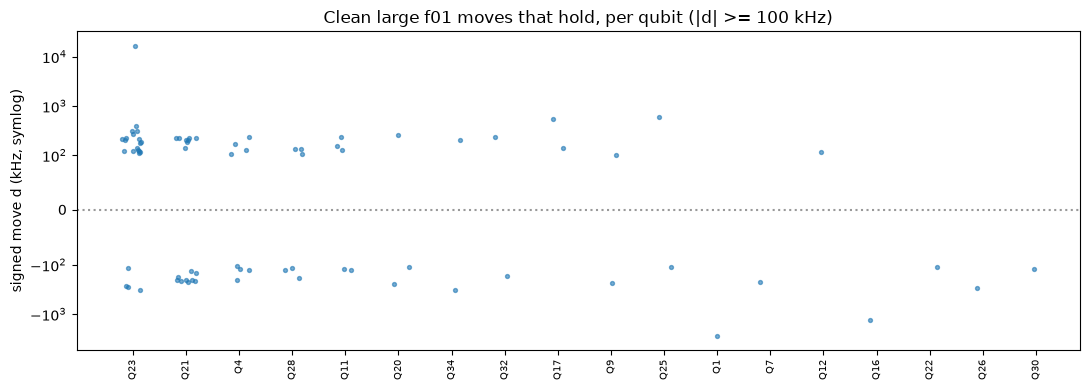

In [20]:
# Qubits ordered by their number of clean holds, with a little jitter so the points don't stack
order = cnt.sort_values(ascending=False).index
xi = {q: i for i, q in enumerate(order)}
jitter = np.random.default_rng(1).uniform(-0.2, 0.2, len(h))

# Every clean hold's signed size, on a log scale beyond BIG
fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(h["qubit"].map(xi) + jitter, h["d"], s=8, alpha=0.6)
ax.set_yscale("symlog", linthresh=BIG)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"Q{q}" for q in order], rotation=90, fontsize=7)
ax.axhline(0, color="0.6", ls=":")
ax.set(
    ylabel="signed move d (kHz, symlog)",
    title=f"Clean large f01 moves that hold, per qubit (|d| >= {BIG:g} kHz)",
)

fig.tight_layout()
fig.savefig(FIG / "d2a_two_level.png", dpi=130)
plt.show()


Q23: 954 clean runs in 15 segments, 22 clean holds; densest 60-day window 2025-02-13 to 2025-04-14 with 21 clean holds
large moves in the window by kind and controller effect:


ctrl,clean,controller-affected
kind,,
back,1,1
holds,21,9
out,2,0


f01 relative to the segment median (kHz), all runs, quantiles: {0.01: -1234.0, 0.1: -8.0, 0.5: 0.0, 0.9: 7.0, 0.99: 377.0}
in the window: {0.01: -62067.0, 0.1: -1299.0, 0.5: 0.0, 0.9: 514.0, 0.99: 11755.0}


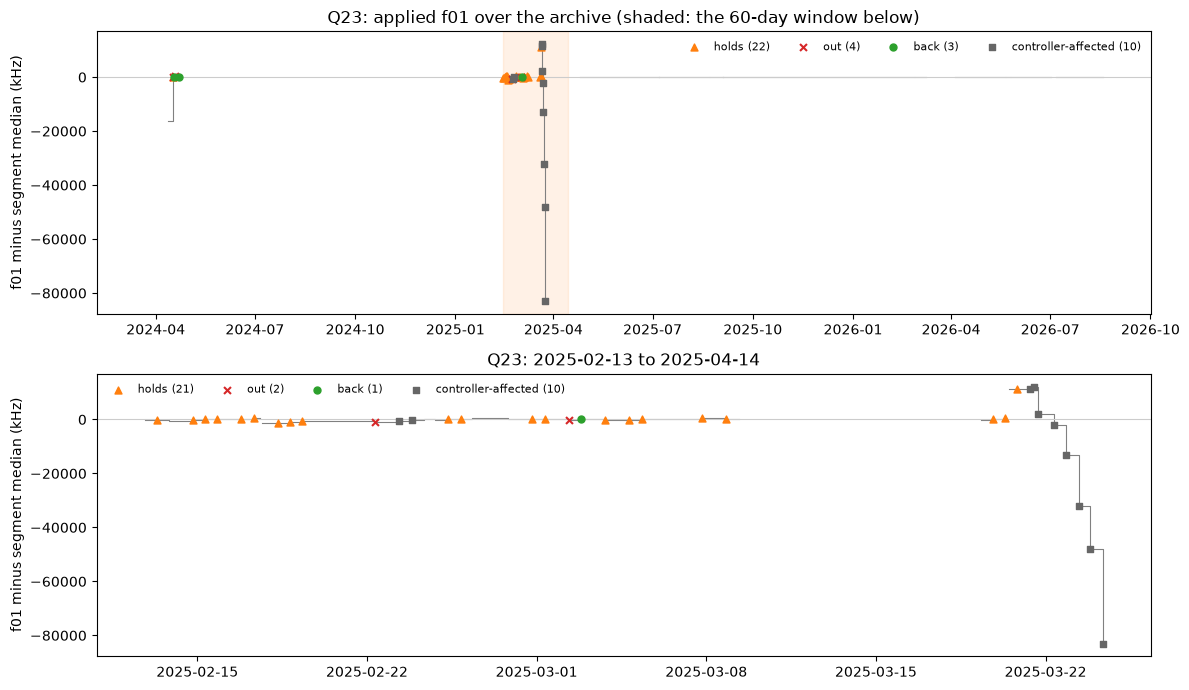

In [21]:
# The qubit with the most clean holds, and its f01 relative to each segment's median (kHz)
tq = cnt.idxmax()
tr = clean[clean["qubit"] == tq].copy()
seg_median = tr.groupby("seg")["y_hz"].transform("median")
tr["f_khz"] = (tr["y_hz"] - seg_median) / 1e3

# The TRACE_DAYS window, starting at one of its clean holds, that holds the most of them
ht = tr.loc[(tr["kind"] == "holds") & ~tr["ctrl"], "t"]
span = pd.Timedelta(days=TRACE_DAYS)
in_win = [int(((ht >= t) & (ht < t + span)).sum()) for t in ht]
w0 = ht.iloc[int(np.argmax(in_win))]
w1 = w0 + span

# The zoom also takes in the 3 days before the window
zoom = tr[(tr["t"] >= w0 - pd.Timedelta(days=3)) & (tr["t"] < w1)]

print(
    f"Q{tq}: {len(tr)} clean runs in {tr['seg'].nunique()} segments, {len(ht)} clean holds; "
    f"densest {TRACE_DAYS}-day window {w0:%Y-%m-%d} to {w1:%Y-%m-%d} with {max(in_win)} clean holds"
)
zm = zoom[zoom["kind"] != ""]
print("large moves in the window by kind and controller effect:")
display(pd.crosstab(zm["kind"], zm["ctrl"].map({False: "clean", True: "controller-affected"})))

# Quantiles of the relative f01, over all runs and in the window
levels = [0.01, 0.1, 0.5, 0.9, 0.99]
print(
    "f01 relative to the segment median (kHz), all runs, quantiles:",
    tr["f_khz"].quantile(levels).round(0).to_dict(),
)
print("in the window:", zoom["f_khz"].quantile(levels).round(0).to_dict())

# Top: the whole archive, with the window shaded; bottom: the window
marks = {"holds": ("^", "C1"), "out": ("x", "C3"), "back": ("o", "C2")}
fig, axs = plt.subplots(2, 1, figsize=(12, 7))
for ax, part in zip(axs, [tr, zoom]):
    # The applied f01 as a step line, one per segment
    for _, g in part.groupby("seg"):
        ax.plot(g["t"], g["f_khz"], drawstyle="steps-post", color="0.5", lw=0.8)

    # The clean large moves, marked by kind, and the controller-affected ones in grey
    for kind, (mk, c) in marks.items():
        k = part[(part["kind"] == kind) & ~part["ctrl"]]
        ax.scatter(k["t"], k["f_khz"], marker=mk, color=c, s=25, zorder=3, label=f"{kind} ({len(k)})")
    k = part[(part["kind"] != "") & part["ctrl"]]
    ax.scatter(
        k["t"], k["f_khz"], marker="s", color="0.4", s=18, zorder=3, label=f"controller-affected ({len(k)})"
    )

    ax.axhline(0, color="0.8", lw=0.8)
    ax.set(ylabel="f01 minus segment median (kHz)")
    ax.legend(frameon=False, fontsize=8, ncol=4)

axs[0].axvspan(w0, w1, color="C1", alpha=0.1)
axs[0].set_title(f"Q{tq}: applied f01 over the archive (shaded: the {TRACE_DAYS}-day window below)")
axs[1].set_title(f"Q{tq}: {w0:%Y-%m-%d} to {w1:%Y-%m-%d}")

fig.tight_layout()
fig.savefig(FIG / "d2a_trajectory.png", dpi=130)
plt.show()


**Results.**

- Clean holds don't return more often than chance. 14 of 38 close pairs return, against a null of 11 [8, 15]. With the controller-affected holds added, 75 of 235 pairs return against 53 [43, 62]. So the return excess comes from the controller.
- Sizes do recur within a qubit. On the 5 qubits with 4 or more clean holds, the median sd of $\log_{10}|d|$ is 0.107, below the null's 0.181 [0.129, 0.319]. Q21 is the clearest case: 17 holds of about 207 kHz, sd 0.07, half up and half down.
- Q23 has the most clean holds (22, about 205 kHz), and 21 of them fall between 2025-02-13 and 2025-04-14. 18 of its 22 holds go up, so it doesn't switch back and forth between two levels.


## 7. Timing: before, at or after the move?

If a TLS switches at the move, coherence should drop at the move. For a hold it should stay low while the new level lasts. A dip a run or two before the move would point to a slower process that starts first.

We compare $z_{r2}$ with quiet runs at offsets −4 to +4 from each clean large move, in the same qubit and segment. A TLS predicts a dip from offset 0 onward for a hold, and only at 0 for an out.


In [22]:
# T2* z_r2 by qubit, segment and position, and the quiet runs as the reference
zmap = s.set_index(["qubit", "seg", "pos"])["z_r2"]
quiet_ref = s.loc[base, ["qubit", "z_r2"]].assign(m=False)

ev = {}
for kind in ["holds", "out"]:
    anchors = s.loc[clean_big & (s["kind"] == kind), ["qubit", "seg", "pos"]]
    for o in EVENT_OFFSETS:
        # z_r2 at the run o positions from each move, in the same qubit and segment
        at = pd.MultiIndex.from_arrays([anchors["qubit"], anchors["seg"], anchors["pos"] + o])
        e = pd.DataFrame(
            {
                "qubit": anchors["qubit"].to_numpy(),
                "z_r2": zmap.reindex(at).to_numpy(),
                "m": True,
            }
        )

        # Set against the quiet runs, with the qubit resampling of section 2
        both = pd.concat([e, quiet_ref], ignore_index=True)
        ev[(kind, o)] = dip(both, both["m"], ~both["m"], "z_r2")

ev = pd.DataFrame(ev).T
ev.index.names = ["kind", "offset"]

# One column block per kind
ev_wide = ev.unstack("kind").swaplevel(0, 1, axis=1).sort_index(axis=1)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ev_wide)


kind    holds                               out                          
         diff     hi      lo qubits runs   diff     hi     lo qubits runs
offset                                                                   
-4     -0.103   1.12  -0.282     12   35 -0.126  0.154 -0.496      7   34
-3     -0.311 0.0301  -0.627     12   37 -0.344   -0.2  -0.73      7   36
-2     -0.123  0.898  -0.322     13   38 -0.253 0.0816 -0.881      7   34
-1     -0.209  0.134  -0.568     13   39 -0.156   1.08 -0.672      7   35
 0     -0.425 -0.353  -0.854     13   40 0.0185  0.394  -0.82      6   35
 1      0.101   0.56  -0.453     13   40 -0.382 0.0401 -0.609      7   35
 2      0.426   1.16   -0.23     10   36 -0.138  0.369   -0.4      7   36
 3      0.216  0.387 -0.0743     10   34  -0.24 0.0535 -0.574      6   33
 4     0.0135   0.63  -0.566     10   36 -0.147  0.319 -0.532      7   35

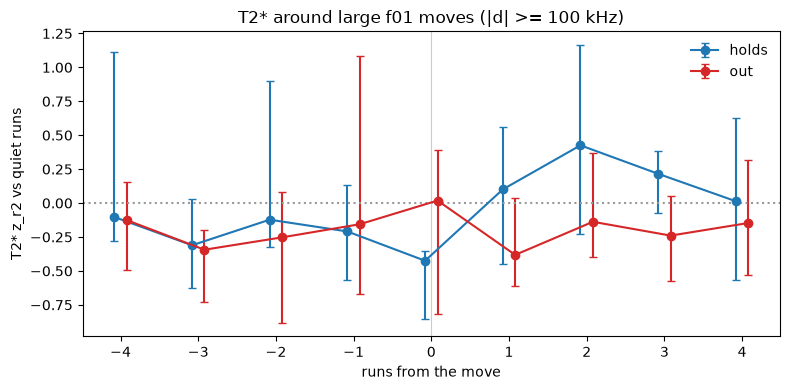

In [23]:
# The dip and its interval at each offset, holds and outs side by side
fig, ax = plt.subplots(figsize=(8, 4))
for kind, c, off in [("holds", "C0", -0.08), ("out", "C3", 0.08)]:
    e = ev.xs(kind, level="kind")
    x = np.array(e.index, dtype=float) + off
    v = e["diff"].astype(float)
    err = [v - e["lo"].astype(float), e["hi"].astype(float) - v]
    ax.errorbar(x, v, yerr=err, fmt="o-", color=c, capsize=3, label=kind)

# No dip, and the move itself
ax.axhline(0, color="0.6", ls=":")
ax.axvline(0, color="0.8", lw=0.8)
ax.set(
    xlabel="runs from the move",
    ylabel="T2* z_r2 vs quiet runs",
    title=f"T2* around large f01 moves (|d| >= {BIG:g} kHz)",
)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(FIG / "d2a_timing.png", dpi=130)
plt.show()

**Results.**

- At clean holds, $z_{r2}$ dips only at the move itself (−0.43 [−0.85, −0.35]). From the next run on it is back at the quiet level (+0.10 [−0.45, 0.56] at offset +1). So the low T2\* doesn't last at the new level.
- At clean outs the move run shows no dip (+0.02 [−0.82, 0.39]). The run that undoes the out gives −0.38 [−0.61, 0.04]. Offset −3 is the only one whose interval excludes 0 (−0.34 [−0.73, −0.20]). With 18 intervals and no correction, one such interval is about what chance gives, so we don't read it as a finding.


## 8. The fridge: thermal cycle and small excursions

**Thermal cycle.** A thermal cycle lets the TLS in the oxides rearrange. If TLS cause the moves, the qubits that move most before the cycle need not be the ones that move most after it. We compare six windows of equal length: A and B just before the cycle, C and D after it, and E and F either side of the 2025-03 outage, which had no thermal cycle. A against B is the control. Per qubit and window we take the rate of clean large moves (holds and outs) per run, the controller-affected rate and the median move size. We compare windows by the rank correlation of the per-qubit rates.

**Rate by quarter.** A window's rate only means something next to the rates around it, so we also give the rates per calendar quarter. The share of runs whose Ramsey value changes by 100 kHz to 1 MHz checks the rate without the applied value.

**Small excursions.** Small mixing-chamber (MIX) warm-ups can't rearrange the oxide, but they could flip a slow fluctuator. We ask whether clean large moves follow them.

<details>
<summary><b>Window and excursion details</b></summary>

- **Windows.** C runs from the end of SETTLING to the start of the second incident, and sets the length. D runs from the end of that incident to the end of the data.
- **Comparisons.** Each pair's rank correlation minus A-B has a qubit-resampled interval. The size change uses qubits with MIN_MOVES moves in both windows.
- **Excursions.** We subtract MIX's rolling median over MIX_BASE and divide by the robust sd per cold epoch to get $z$. Each run gets the largest $z$ in the EXC_HOURS before it, from at least MIN_READ cold readings in one epoch. A run with $z \ge$ Z_EXC follows an excursion.
- **Statistics.** The large-move rate after an excursion over the rate after none, and the rank correlation of each run's move rate with its $z$. The null shifts $z$ in time within each epoch by at least a week, which keeps how excursions cluster.

</details>


In [24]:
# The thermal cycle, the settling after it, the second incident and the 2025-03 outage
inc0 = periods.INCIDENTS[0].period[0]  # start of the thermal cycle
settled = periods.SETTLING[0][1]  # end of the settling after it
inc1 = periods.INCIDENTS[1].period  # the second incident
out_mar = periods.OUTAGES[1]  # the 2025-03 outage
W = inc1[0] - settled  # window length (C)

# A and B just before the cycle, C and D after it, E and F either side of the 2025-03 outage
win = {
    "A": (inc0 - 2 * W, inc0 - W),
    "B": (inc0 - W, inc0),
    "C": (settled, inc1[0]),
    "D": (inc1[1], clean["t"].max() + pd.Timedelta("1s")),
    "E": (out_mar[0] - W, out_mar[0]),
    "F": (out_mar[1], out_mar[1] + W),
}

# Clean runs with a change, labelled by window
wr = clean[clean["d"].notna()].copy()
in_window = [periods.within(wr["t"], w) for w in win.values()]
wr["win"] = np.select(in_window, list(win), "")
wr = wr[wr["win"] != ""]

# A large move is a hold or an out (a back is the second half of an out); clean or controller-affected
is_move = (wr["d"].abs() >= BIG) & (wr["kind"] != "back")
wr["event"] = is_move & ~wr["ctrl"]
wr["ctrl_event"] = is_move & wr["ctrl"]
wr["hold"] = (wr["kind"] == "holds") & ~wr["ctrl"]
wr["l"] = np.log10(wr["d"].abs())

# Per window: its span, runs, qubits, moves, the move and hold rates, and the move size
pooled = wr.groupby("win").agg(
    start=("t", "min"),
    end=("t", "max"),
    runs=("d", "size"),
    qubits=("qubit", "nunique"),
    moves=("event", "sum"),
    move_rate=("event", "mean"),
    ctrl_rate=("ctrl_event", "mean"),
    hold_rate=("hold", "mean"),
)
moves_by_win = wr[wr["event"]].groupby("win")["d"]
pooled["median_abs_d_kHz"] = moves_by_win.apply(lambda v: v.abs().median())

print(f"window length {W.days} days")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pooled)

# Rate by calendar quarter over the whole archive, and the Ramsey value's own large changes
qr = s[s["d"].notna()].copy()
qr["quarter"] = qr["t"].dt.to_period("Q")
q_move = (qr["d"].abs() >= BIG) & (qr["kind"] != "back")
ri_big = ri.abs().between(BIG, 1e3, inclusive="left").astype(float).where(ri.notna())
quarterly = pd.DataFrame(
    {
        "runs": qr.groupby("quarter").size(),
        "qubits": qr.groupby("quarter")["qubit"].nunique(),
        "clean move rate": (q_move & ~qr["ctrl"]).groupby(qr["quarter"]).mean(),
        "controller-affected rate": (q_move & qr["ctrl"]).groupby(qr["quarter"]).mean(),
        "warned share": qr.groupby("quarter")["warned"].mean(),
        f"Ramsey {BIG:g} kHz to 1 MHz share": ri_big.reindex(qr.index).groupby(qr["quarter"]).mean(),
    }
)
print("rates per run with a change, by quarter:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(quarterly)


window length 89 days


,start,end,runs,qubits,moves,move_rate,ctrl_rate,hold_rate,median_abs_d_kHz
win,,,,,,,,,
A,2025-09-11 19:44:09,2025-12-09 19:44:53,5247,30,7,0.00133,0.00724,0.000953,181
B,2025-12-10 08:45:16,2026-03-08 19:42:41,5219,30,3,0.000575,0.00211,0.000575,136
C,2026-04-04 19:44:57,2026-07-01 19:38:11,5052,30,30,0.00594,0.0352,0.00297,205
D,2026-07-06 08:45:40,2026-08-18 08:45:39,2547,30,16,0.00628,0.0381,0.00236,184
E,2024-12-10 20:05:19,2025-03-09 08:00:20,4657,30,23,0.00494,0.015,0.00408,188
F,2025-03-19 19:45:27,2025-06-15 08:45:23,4996,30,20,0.004,0.0108,0.0036,179


rates per run with a change, by quarter:


,runs,qubits,clean move rate,controller-affected rate,warned share,Ramsey 100 kHz to 1 MHz share
quarter,,,,,,
2024Q2,873,30,0.0103,0.0218,0.0401,NaN
2024Q3,29,29,0,0.103,0.069,0
2024Q4,3944,29,0.000254,0.0129,0.0228,0.000254
2025Q1,4146,30,0.00748,0.0191,0.0434,0.0195
2025Q2,5190,30,0.00231,0.00732,0.0422,0.00848
2025Q3,5366,30,0.00205,0.00485,0.0403,0.00581
2025Q4,5427,30,0.00129,0.00516,0.0392,0.00719
2026Q1,3930,30,0.000763,0.00254,0.0364,0.00204
2026Q2,4993,30,0.00601,0.0352,0.0755,0.0371


In [25]:
# Per qubit and window: runs, clean moves, and the move and hold rates
pq = (
    wr.groupby(["qubit", "win"])
    .agg(
        runs=("d", "size"),
        moves=("event", "sum"),
        rate=("event", "mean"),
        hold_rate=("hold", "mean"),
    )
    .unstack("win")
)
rate = pq["rate"].dropna()
pairs = [("A", "B"), ("B", "C"), ("A", "C"), ("C", "D"), ("B", "D"), ("E", "F")]


def corr(x: pd.DataFrame, a: str, b: str) -> float:
    """Spearman rank correlation of two window columns."""
    return x[a].rank().corr(x[b].rank())


# Resample qubits for the interval on each correlation
rng = np.random.default_rng(0)
boot = np.empty((N_BOOT, len(pairs)))
for k in range(N_BOOT):
    i = rng.integers(0, len(rate), len(rate))
    boot[k] = [corr(rate.iloc[i], a, b) for a, b in pairs]

# Rate and hold-rate correlation for each pair of windows
hold_rate = pq["hold_rate"].dropna()
ct = pd.DataFrame(
    {
        "rate corr": [corr(rate, a, b) for a, b in pairs],
        "hold-rate corr": [corr(hold_rate, a, b) for a, b in pairs],
        "lo": np.nanpercentile(boot, 2.5, 0),
        "hi": np.nanpercentile(boot, 97.5, 0),
    },
    index=[f"{a}-{b}" for a, b in pairs],
)

# Each pair against the A-B control
for j, (a, b) in enumerate(pairs[1:], 1):
    label = f"{a}-{b}"
    dd = boot[:, j] - boot[:, 0]
    dd_lo, dd_hi = np.nanpercentile(dd, [2.5, 97.5])
    ct.loc[label, "minus A-B"] = ct.iloc[j, 0] - ct.iloc[0, 0]
    ct.loc[label, "minus A-B lo"] = dd_lo
    ct.loc[label, "minus A-B hi"] = dd_hi

print(f"qubits in all {len(win)} windows: {len(rate)}")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ct)

# Move size per qubit and window: the median log10|d| and the number of clean moves
ml = wr[wr["event"]].groupby(["qubit", "win"])["l"].agg(["median", "size"]).unstack("win")

# Change in the median size between two windows, for qubits with MIN_MOVES moves in both
size_tab = {}
for a, b in pairs:
    k = (ml["size"][a] >= MIN_MOVES) & (ml["size"][b] >= MIN_MOVES)
    dl = (ml["median"][b] - ml["median"][a])[k]
    size_tab[f"{a}-{b}"] = {
        "qubits": int(k.sum()),
        "median change log10|d|": dl.median(),
        "median |change|": dl.abs().median(),
    }
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.DataFrame(size_tab).T)

# Which qubits move most in each window
top = {w: rate[w].nlargest(5).index.tolist() for w in win}
print("five qubits with the highest clean move rate per window:", top)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pq[["moves", "rate"]].sort_values(("rate", "B"), ascending=False))


/home/airfan/cal_eng/secondment/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/airfan/cal_eng/secondment/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


qubits in all 6 windows: 30


,rate corr,hold-rate corr,lo,hi,minus A-B,minus A-B lo,minus A-B hi
A-B,-0.111,-0.111,-0.214,-0.0345,NaN,NaN,NaN
B-C,-0.111,-0.111,-0.199,-0.0496,4.55e-05,-0.0816,0.0867
A-C,0.309,0.309,-0.13,0.83,0.42,-0.0332,0.95
C-D,0.401,0.401,-0.0891,1,0.512,-0.0231,1.1
B-D,-0.0889,-0.0889,-0.175,-0.0345,0.0219,-0.0456,0.102
E-F,0.11,0.242,-0.243,0.556,0.221,-0.144,0.658


,qubits,median change log10|d|,median |change|
A-B,0,NaN,NaN
B-C,0,NaN,NaN
A-C,1,0.059,0.059
C-D,1,-0.0533,0.0533
B-D,0,NaN,NaN
E-F,1,0.0252,0.0252


five qubits with the highest clean move rate per window: {'A': [21, 4, 20, 1, 5], 'B': [1, 28, 30, 4, 5], 'C': [21, 11, 16, 1, 4], 'D': [21, 7, 1, 4, 5], 'E': [23, 12, 18, 1, 4], 'F': [4, 23, 28, 20, 25]}


moves                      rate                                       
win       A  B   C   D   E  F       A       B       C      D       E       F
qubit                                                                       
1         0  1   0   0   0  0       0 0.00578       0      0       0       0
30        0  1   0   0   0  0       0 0.00575       0      0       0       0
28        0  1   0   0   0  3       0 0.00575       0      0       0  0.0176
6         0  0   0   0   0  0       0       0       0      0       0       0
5         0  0   0   0   0  0       0       0       0      0       0       0
4         1  0   0   0   0  5 0.00571       0       0      0       0  0.0299
10        0  0   0   0   0  0       0       0       0      0       0       0
11        0  0  10   0   0  0       0       0  0.0595      0       0       0
12        0  0   0   0   2  0       0       0       0      0  0.0126       0
14        0  0   0   0   0  1       0       0       0      0       0 0.00588
15        0  0   0   0   0  0       0       0       0      0       0       0
16        0  0   1   0   0  0       0       0 0.00595      0       0       0
7         0  0   0   3   0  0       0       0       0 0.0353       0       0
9         0  0   0   0   0  0       0       0       0      0       0       0
18        0  0   0   0   1  0       0       0       0      0 0.00629       0
17        0  0   0   0   0  0       0       0       0      0       0       0
19        0  0   0   0   0  0       0       0       0      0       0       0
20        1  0   0   0   0  2 0.00571       0       0      0       0   0.012
23        0  0   0   0  20  3       0       0       0      0   0.435  0.0268
24        0  0   0   0   0  0       0       0       0      0       0       0
21        5  0  19  13   0  0  0.0287       0   0.114  0.153       0       0
22        0  0   0   0   0  0       0       0       0      0       0       0
26        0  0   0   0   0  0       0       0       0      0       0       0
25        0  0   0   0   0  2       0       0       0      0       0   0.012
27        0  0   0   0   0  0       0       0       0      0       0       0
31        0  0   0   0   0  0       0       0       0      0       0       0
32        0  0   0   0   0  2       0       0       0      0       0  0.0118
33        0  0   0   0   0  0       0       0       0      0       0       0
34        0  0   0   0   0  2       0       0       0      0       0  0.0118
35        0  0   0   0   0  0       0       0       0      0       0       0

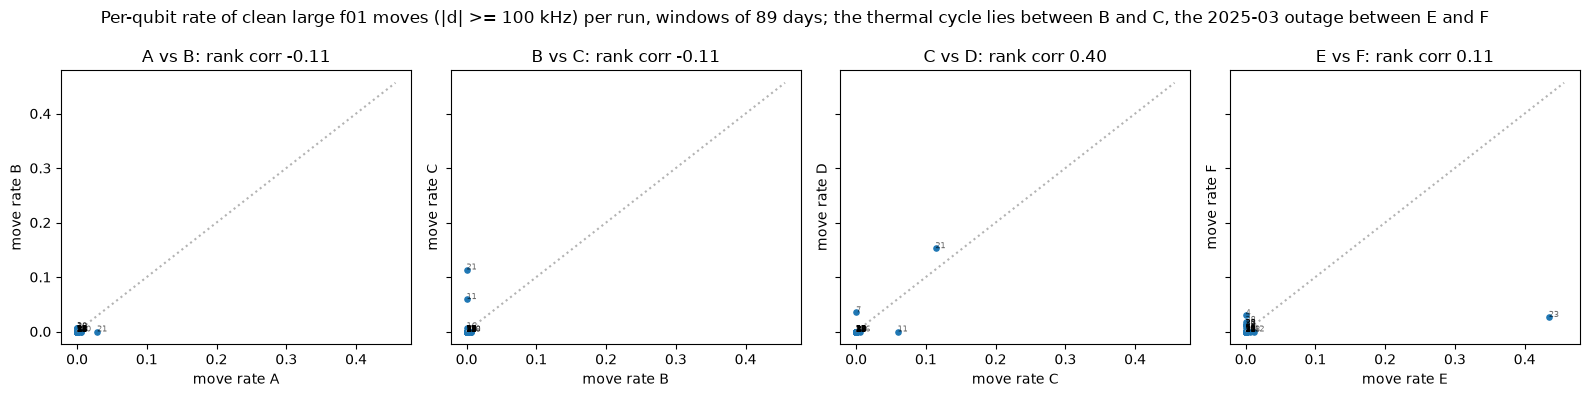

In [26]:
# Per-qubit move rate in one window against the next, with the diagonal for reference
fig, axs = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
top_rate = rate.max().max() * 1.05
for a_, (x_, y_) in zip(axs, [("A", "B"), ("B", "C"), ("C", "D"), ("E", "F")]):
    a_.scatter(rate[x_], rate[y_], s=14)
    for q, row in rate.iterrows():
        a_.annotate(str(q), (row[x_], row[y_]), fontsize=6, alpha=0.6)
    a_.plot([0, top_rate], [0, top_rate], color="0.7", ls=":")
    a_.set(
        xlabel=f"move rate {x_}",
        ylabel=f"move rate {y_}",
        title=f"{x_} vs {y_}: rank corr {corr(rate, x_, y_):.2f}",
    )

fig.suptitle(
    f"Per-qubit rate of clean large f01 moves (|d| >= {BIG:g} kHz) per run, windows of "
    f"{W.days} days; the thermal cycle lies between B and C, the 2025-03 outage between E and F"
)
fig.tight_layout()
fig.savefig(FIG / "d2a_thermal_cycle.png", dpi=130)
plt.show()


In [27]:
# MIX on cold DS4 rows (mK) with its cold epoch, as UTC with no timezone like the run map
fr = load_fridge()
fr_cold = cold_mask(fr)
mix = fr.loc[fr_cold, MIX] * 1e3
fr_ep = cold_epochs(fr)[fr_cold].astype(int)
utc = mix.index.tz_convert("UTC").tz_localize(None)
mix.index = utc
fr_ep.index = utc

# Excursion z: MIX minus its rolling median (to remove slow changes), in robust sd, per epoch
slow = mix.groupby(fr_ep).transform(
    lambda m: m.rolling(MIX_BASE, center=True, min_periods=1).median()
)
mix_resid = mix - slow
mz = mix_resid.groupby(fr_ep).transform(lambda m: m / methods.rsd(m.to_numpy()))

epoch_rows = fr_ep.value_counts().sort_index().to_dict()
print(
    f"cold DS4 rows {len(mz)} in epochs {epoch_rows}; "
    f"rows with z >= {Z_EXC:g}: {int((mz >= Z_EXC).sum())}"
)

# Per calibrate_1q run: the chip's clean large moves (holds and outs, as above) and its
# qubit-runs with a change
cr = clean[clean["d"].notna()]
cr = cr.assign(event=(cr["d"].abs() >= BIG) & (cr["kind"] != "back") & ~cr["ctrl"])
runs_fr = (
    cr.groupby("run")
    .agg(t=("t", "first"), n=("event", "size"), events=("event", "sum"))
    .sort_values("t")
)

# The cold readings in the EXC_HOURS before each run
zt = mz.index.to_numpy("datetime64[ns]")
zv = mz.to_numpy()
ze = fr_ep.to_numpy()
rt = runs_fr["t"].to_numpy("datetime64[ns]")
w_lo = np.searchsorted(zt, rt - np.timedelta64(EXC_HOURS, "h"), side="right")
w_hi = np.searchsorted(zt, rt, side="right")

# Keep runs with MIN_READ readings there, all in one epoch
enough = w_hi - w_lo >= MIN_READ
first_epoch = ze[np.minimum(w_lo, len(ze) - 1)]
last_epoch = ze[np.maximum(w_hi - 1, 0)]
w_ok = enough & (first_epoch == last_epoch)
w_lo, w_hi = w_lo[w_ok], w_hi[w_ok]
runs_fr = runs_fr[w_ok].copy()


def run_max(z: np.ndarray) -> np.ndarray:
    """Largest z in each run's window."""
    return np.array([z[a:b].max() for a, b in zip(w_lo, w_hi)])


def exc_stats(zmax: np.ndarray) -> tuple[float, float]:
    """Large-move rate per qubit-run after an excursion over the rate after none, and the rank
    correlation of each run's move rate with its largest z."""
    after = zmax >= Z_EXC
    n, k = runs_fr["n"].to_numpy(), runs_fr["events"].to_numpy()

    # The rate ratio needs at least one run after an excursion
    if after.any():
        rate_after = k[after].sum() / n[after].sum()
        rate_none = k[~after].sum() / n[~after].sum()
        ratio = rate_after / rate_none
    else:
        ratio = np.nan

    rho = pd.Series(zmax).rank().corr(pd.Series(k / n).rank())
    return ratio, rho


# Observed: the largest z and MIX before each run
runs_fr["zmax"] = run_max(zv)
mix_v = mix.to_numpy()
runs_fr["mix_max_mK"] = [mix_v[a:b].max() for a, b in zip(w_lo, w_hi)]
exc_ratio, exc_rho = exc_stats(runs_fr["zmax"].to_numpy())

# Null: shift the z series circularly within each epoch, by at least MIN_SHIFT rows
rng_fr = np.random.default_rng(0)
ep_rows = [np.flatnonzero(ze == k) for k in np.unique(ze)]
null_fr = np.empty((N_SHUFFLE, 2))
for i in range(N_SHUFFLE):
    zs = zv.copy()
    for b in ep_rows:
        # Epochs too short to shift by MIN_SHIFT either way stay put
        if len(b) > 2 * MIN_SHIFT:
            shift = rng_fr.integers(MIN_SHIFT, len(b) - MIN_SHIFT)
            zs[b] = np.roll(zv[b], shift)
    null_fr[i] = exc_stats(run_max(zs))

# Runs kept, and how many follow an excursion
after_exc = runs_fr["zmax"] >= Z_EXC
t_first, t_last = runs_fr["t"].min(), runs_fr["t"].max()
print(
    f"runs with {MIN_READ}+ cold readings in the {EXC_HOURS} h before: {len(runs_fr)}, "
    f"{t_first:%Y-%m-%d} to {t_last:%Y-%m-%d}; after an excursion: {int(after_exc.sum())}"
)

# Clean large moves and qubit-runs after an excursion, and otherwise
moves_after = runs_fr.loc[after_exc, "events"].sum()
qruns_after = runs_fr.loc[after_exc, "n"].sum()
moves_other = runs_fr.loc[~after_exc, "events"].sum()
qruns_other = runs_fr.loc[~after_exc, "n"].sum()
print(
    f"clean large moves per qubit-run: after an excursion {moves_after} of {qruns_after}, "
    f"otherwise {moves_other} of {qruns_other}"
)

# Each statistic against its shifted null
for j, (name, obs) in enumerate([("rate ratio", exc_ratio), ("rank correlation", exc_rho)]):
    nv = null_fr[:, j]
    nv_lo, nv_hi = np.nanpercentile(nv, 2.5), np.nanpercentile(nv, 97.5)
    print(
        f"{name} {obs:.3g}: shifted null median {np.nanmedian(nv):.3g}, "
        f"95% {nv_lo:.3g} to {nv_hi:.3g}; share of the null at or above {np.mean(nv >= obs):.3g}"
    )

print("the ten runs with the largest excursion before them:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(runs_fr.nlargest(10, "zmax"))


cold DS4 rows 1452 in epochs {0: 879, 1: 328, 2: 18, 3: 227}; rows with z >= 3: 50
runs with 3+ cold readings in the 24 h before: 640, 2025-08-02 to 2026-08-18; after an excursion: 55
clean large moves per qubit-run: after an excursion 3 of 1648, otherwise 48 of 17527
rate ratio 0.665: shifted null median 1.29, 95% 0.509 to 2.5; share of the null at or above 0.93
rank correlation -0.034: shifted null median 0.0172, 95% -0.0587 to 0.0862; share of the null at or above 0.907
the ten runs with the largest excursion before them:


,t,n,events,zmax,mix_max_mK
run,,,,,
813,2025-12-01 08:45:16,30,0,22.4,13.3
814,2025-12-01 19:43:18,30,0,22.4,13.3
647,2025-09-08 08:45:22,30,0,12.8,11.5
648,2025-09-08 19:44:08,30,0,12.8,11.5
676,2025-09-23 08:45:22,30,0,9.53,10.6
677,2025-09-23 19:43:54,30,0,9.53,10.6
775,2025-11-12 08:45:16,30,0,6.47,10.6
777,2025-11-12 21:23:01,30,0,6.47,10.6
793,2025-11-21 08:45:16,30,0,6.35,10.8


**Results.**

- The windows are 89 days long. The clean move rate per run is 0.0013 in A and 0.0006 in B before the thermal cycle, 0.0059 in C and 0.0063 in D after it, and 0.0049 in E and 0.0040 in F around the 2025-03 outage. The controller-affected rate is 3 to 6 times the clean rate in every window.
- By quarter, the clean rate falls from 0.0075 in 2025Q1 to 0.0008 in 2026Q1, then rises to 0.006 in 2026Q2 and 2026Q3. The Ramsey check follows the same path (0.020, 0.002, then 0.037). So A and B fall in a quiet stretch, and C and D are back near the 2025Q1 level.
- Clean moves sit on a few qubits, so the rank correlations are mostly ties and none differs from A-B. Q21 moves most in A, C and D, on both sides of the thermal cycle. Q23 leads E, Q4 leads F, and Q11 is second in C. The size comparison is empty. The five-qubit lists in the output are padded with qubits that have no moves.
- Clean large moves are no more common after a MIX excursion: a rate ratio of 0.67 against a shifted null of 1.29 [0.51, 2.5].


## 9. Switching times, rate stability, the size of outs and same-run moves

One TLS that doesn't change switches at random times with a fixed rate. We test three consequences on the clean large moves (holds and outs), then check whether qubits move at the same run.

- **Regularity.** The coefficient of variation (CV) of the gaps between a qubit's moves is about 1 at a fixed rate, above 1 for bursts and below 1 for regular moves.
- **Stability.** The dispersion of a qubit's move counts over blocks of BLOCK_DAYS is about 1 at a constant rate. The null keeps each segment's rate, so a value above it means the rate changes within segments.
- **Outs against holds.** If outs come from the same TLS as holds, a qubit's outs and holds should have the same size.
- **Same-run moves.** A TLS sits next to one qubit, so qubits should move independently. Shared electronics or a chip-wide event would move several at once.

<details>
<summary><b>Formulas and nulls</b></summary>

- **Regularity.** With $g$ the gaps in clean runs within a segment, $\text{CV} = \operatorname{sd}(g)/\operatorname{mean}(g)$. The null shuffles the moves within each qubit and segment. A qubit needs MIN_GAPS gaps. The mean gap in days is a rough switching time.
- **Stability.** Block $b$ of $B$ has $k_b$ moves in $n_b$ runs, with pooled rate $p = \sum k_b / \sum n_b$:

$$D = \frac{1}{B - 1}\sum_b \frac{(k_b - n_b p)^2}{n_b\,p(1 - p)}.$$

  Blocks need MIN_BLOCK_RUNS runs. The null shuffles the moves within each segment.
- **Outs against holds.** On qubits with MIN_MOVES of each, the median per-qubit ratio of out size to hold size, and the rank correlation of their median sizes.
- **Same-run moves.** The null draws each qubit-run as a move at the chip's rate in that quarter (N_SHUFFLE draws). We count runs with at least CO_COUNTS moves.

</details>


In [28]:
# Clean runs with a change, in time order within each qubit and segment
cs = clean[clean["d"].notna()].sort_values(["qubit", "seg", "t"]).reset_index(drop=True)

# An event is a clean large move that holds or goes out; i is the run index within the segment
cs["event"] = ((cs["d"].abs() >= BIG) & (cs["kind"] != "back") & ~cs["ctrl"]).to_numpy()
cs["i"] = cs.groupby(["qubit", "seg"]).cumcount()

# Per qubit: (run index, event flag, time) for each of its segments
groups = {}
for q, gq in cs.groupby("qubit"):
    groups[q] = [
        (g["i"].to_numpy(), g["event"].to_numpy(), g["t"].to_numpy("datetime64[ns]"))
        for _, g in gq.groupby("seg")
    ]


def gaps(segs, ev=None) -> np.ndarray:
    """Gaps in runs between consecutive events within each segment of one qubit (ev overrides
    the event flags)."""
    out = []
    for k, (i, e, _) in enumerate(segs):
        flags = e if ev is None else ev[k]
        out.append(np.diff(i[flags]))
    return np.concatenate(out or [np.array([])])


def cv(g: np.ndarray) -> float:
    """Coefficient of variation of the gaps, if there are MIN_GAPS of them."""
    return g.std() / g.mean() if len(g) >= MIN_GAPS else np.nan


# One generator for the shuffles here and in the next two cells, so run them in order
rng = np.random.default_rng(0)

reg = {}
for q, segs in groups.items():
    g = gaps(segs)
    if len(g) < MIN_GAPS:
        continue

    # Null: the event flags shuffled within each segment, keeping their number
    null = []
    for _ in range(N_SHUFFLE):
        shuffled = [rng.permutation(e) for _, e, _ in segs]
        null.append(cv(gaps(segs, shuffled)))
    null = np.array(null)

    # Gaps in days, for a rough switching time
    days = np.concatenate([np.diff(t[e]) / np.timedelta64(1, "D") for _, e, t in segs])

    reg[q] = {
        "events": int(sum(e.sum() for _, e, _ in segs)),
        "gaps": len(g),
        "mean_gap_runs": g.mean(),
        "mean_gap_days": days.mean(),
        "cv": cv(g),
        "null_median": np.nanmedian(null),
        "null_hi": np.nanpercentile(null, 97.5),
        "null_lo": np.nanpercentile(null, 2.5),
    }
reg = pd.DataFrame(reg).T

# How many qubits are burstier or more regular than their null
n_above = int((reg["cv"] > reg["null_hi"]).sum())
n_below = int((reg["cv"] < reg["null_lo"]).sum())
print(
    f"qubits with >= {MIN_GAPS} gaps: {len(reg)}; median CV {reg['cv'].median():.3g} "
    f"against a null median {reg['null_median'].median():.3g}; "
    f"above the null 97.5%: {n_above}, below the 2.5%: {n_below}"
)

gap_days = reg["mean_gap_days"]
print(
    f"mean gap between events: median over qubits {gap_days.median():.3g} days "
    f"(range {gap_days.min():.3g} to {gap_days.max():.3g})"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(reg.sort_values("events", ascending=False))


qubits with >= 10 gaps: 2; median CV 0.766 against a null median 1.19; above the null 97.5%: 0, below the 2.5%: 1
mean gap between events: median over qubits 2.13 days (range 1.19 to 3.07)


,events,gaps,mean_gap_runs,mean_gap_days,cv,null_median,null_hi,null_lo
21,37,32,6.03,3.07,0.853,1.69,2.51,1.07
23,26,21,2.14,1.19,0.68,0.69,1.04,0.5


In [29]:
# Blocks of BLOCK_DAYS from the start of the data
cs["block"] = ((cs["t"] - cs["t"].min()) // pd.Timedelta(days=BLOCK_DAYS)).astype(int)


def dispersion(k: np.ndarray, n: np.ndarray) -> float:
    """Dispersion of event counts k over blocks of n runs against a constant rate (about 1 when
    constant)."""
    p = k.sum() / n.sum()
    if not (0 < p < 1 and len(k) >= 3):
        return np.nan
    return ((k - n * p) ** 2 / (n * p * (1 - p))).sum() / (len(k) - 1)


def block_counts(e: np.ndarray, b_: np.ndarray, blocks: np.ndarray) -> np.ndarray:
    """Events per block, from each run's event flag e and block b_."""
    return np.array([e[b_ == b].sum() for b in blocks])


def shuffle_within(e: np.ndarray, groups: list[np.ndarray]) -> np.ndarray:
    """Event flags e shuffled within each group of run positions."""
    out = e.copy()
    for i in groups:
        out[i] = rng.permutation(e[i])
    return out


stab = {}
for q, g in cs.groupby("qubit"):
    # Keep the qubit's blocks with MIN_BLOCK_RUNS runs
    runs_per_block = g.groupby("block").size()
    kept_blocks = runs_per_block[runs_per_block >= MIN_BLOCK_RUNS].index
    g = g[g["block"].isin(kept_blocks)]

    # Block of each run, its event flag, and the runs per block
    b_, e_ = g["block"].to_numpy(), g["event"].to_numpy()
    blocks = np.unique(b_)
    n_ = np.array([(b_ == b).sum() for b in blocks])

    # Skip qubits with too few blocks or events
    obs = dispersion(block_counts(e_, b_, blocks), n_)
    if np.isnan(obs) or e_.sum() < MIN_GAPS:
        continue

    # Null: the events shuffled across the kept runs of each segment, so each segment keeps its
    # own rate
    seg_ = g["seg"].to_numpy()
    seg_rows = [np.flatnonzero(seg_ == k) for k in np.unique(seg_)]
    null = []
    for _ in range(N_SHUFFLE):
        shuffled = block_counts(shuffle_within(e_, seg_rows), b_, blocks)
        null.append(dispersion(shuffled, n_))
    null = np.array(null)

    block_rate = block_counts(e_, b_, blocks) / n_
    stab[q] = {
        "blocks": len(blocks),
        "segments": len(seg_rows),
        "events": int(e_.sum()),
        "dispersion": obs,
        "null_median": np.median(null),
        "null_hi": np.percentile(null, 97.5),
        "share_null_ge_obs": (null >= obs).mean(),
        "min_block_rate": block_rate.min(),
        "max_block_rate": block_rate.max(),
    }
stab = pd.DataFrame(stab).T

n_above = int((stab["dispersion"] > stab["null_hi"]).sum())
print(
    f"blocks of {BLOCK_DAYS} days with >= {MIN_BLOCK_RUNS} runs; "
    f"qubits with >= 3 blocks and >= {MIN_GAPS} events: {len(stab)}; "
    f"median dispersion {stab['dispersion'].median():.3g} "
    f"against a null median {stab['null_median'].median():.3g}; "
    f"above the null 97.5%: {n_above}"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(stab.sort_values("dispersion", ascending=False))


blocks of 60 days with >= 20 runs; qubits with >= 3 blocks and >= 10 events: 4; median dispersion 6.97 against a null median 7.13; above the null 97.5%: 0


,blocks,segments,events,dispersion,null_median,null_hi,share_null_ge_obs,min_block_rate,max_block_rate
23,10,13,23,40.2,40.2,40.2,1,0,0.404
21,13,15,37,9.42,8.93,10.9,0.189,0,0.2
11,13,15,10,4.53,5.34,6.76,0.946,0,0.0631
28,13,15,11,3.59,2.13,4.54,0.084,0,0.0598


In [30]:
# log10|d| of every clean large move that holds or goes out
lo_ = clean[clean["kind"].isin(["holds", "out"]) & ~clean["ctrl"]]
lo_ = lo_.assign(l=np.log10(lo_["d"].abs()))

# Median size and count per qubit and kind; keep qubits with MIN_MOVES of each
oh = lo_.groupby(["qubit", "kind"])["l"].agg(["median", "size"]).unstack("kind")
both_kinds = (oh["size"]["holds"] >= MIN_MOVES) & (oh["size"]["out"] >= MIN_MOVES)
oh = oh[both_kinds]
mo, mh = oh["median"]["out"], oh["median"]["holds"]

# Resample qubits for the interval on the rank correlation (same rng as the last two cells)
bc = []
for _ in range(N_BOOT):
    i = rng.integers(0, len(oh), len(oh))
    bc.append(mo.iloc[i].rank().corr(mh.iloc[i].rank()))

# Pooled sizes
med_out = lo_.loc[lo_["kind"] == "out", "d"].abs().median()
med_holds = lo_.loc[lo_["kind"] == "holds", "d"].abs().median()
print(f"pooled median |d|: outs {med_out:.0f} kHz, holds {med_holds:.0f} kHz")

# Per qubit: rank correlation of the sizes, and the typical ratio
oh_corr = mo.rank().corr(mh.rank())
bc_lo, bc_hi = np.nanpercentile(bc, 2.5), np.nanpercentile(bc, 97.5)
ratio_med = (10 ** (mo - mh)).median()
print(
    f"qubits with >= {MIN_MOVES} outs and holds: {len(oh)}; "
    f"rank corr of median log10|d| (out vs holds) {oh_corr:.3g} [{bc_lo:.3g}, {bc_hi:.3g}]; "
    f"median per-qubit ratio out/holds {ratio_med:.3g}"
)


/home/airfan/cal_eng/secondment/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


pooled median |d|: outs 180 kHz, holds 194 kHz
qubits with >= 3 outs and holds: 4; rank corr of median log10|d| (out vs holds) 0.6 [-1, 1]; median per-qubit ratio out/holds 1.04


In [31]:
# Same-run moves: per run, the qubits with a change and their clean large moves
co = cs.assign(quarter=cs["t"].dt.to_period("Q"))
q_rate = co.groupby("quarter")["event"].mean()
per_run = co.groupby("run").agg(
    t=("t", "first"), n=("event", "size"), k=("event", "sum"), quarter=("quarter", "first")
)

# Null: each qubit-run is a move with its quarter's rate, independently of the other qubits
rng_co = np.random.default_rng(0)
p_run = per_run["quarter"].map(q_rate).to_numpy(float)
sims = rng_co.binomial(per_run["n"].to_numpy(), p_run, size=(N_SHUFFLE, len(per_run)))

# Runs with at least m moves, observed against the null
co_tab = {}
for m in CO_COUNTS:
    null_m = (sims >= m).sum(1)
    obs_m = int((per_run["k"] >= m).sum())
    co_tab[f">= {m} moves"] = {
        "runs": obs_m,
        "null median": np.median(null_m),
        "null lo": np.percentile(null_m, 2.5),
        "null hi": np.percentile(null_m, 97.5),
        "share null >= runs": (null_m >= obs_m).mean(),
    }
print(f"runs {len(per_run)}, clean large moves {int(per_run['k'].sum())}")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.DataFrame(co_tab).T)

print("the five runs with the most clean large moves:")
display(per_run.nlargest(5, "k"))


runs 1229, clean large moves 120


,runs,null median,null lo,null hi,share null >= runs
>= 2 moves,7,8,3,14,0.746
>= 3 moves,0,0,0,2,1
>= 5 moves,0,0,0,0,1


the five runs with the most clean large moves:


,t,n,k,quarter
run,,,,
264,2025-02-18 19:45:33,30,2,2025Q1
301,2025-03-19 19:45:27,30,2,2025Q1
312,2025-03-24 08:45:22,30,2,2025Q1
984,2026-02-25 20:42:06,30,2,2026Q1
1120,2026-05-19 08:45:16,30,2,2026Q2


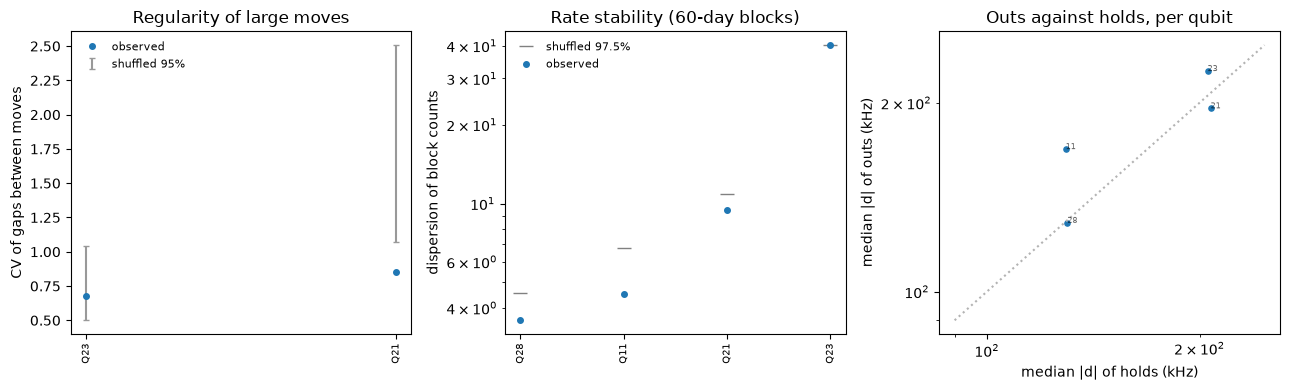

In [32]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4))

# Left: each qubit's gap CV against its shuffled 95% range
ax = axs[0]
o = reg.sort_values("cv").index
null_err = [
    reg.loc[o, "null_median"] - reg.loc[o, "null_lo"],
    reg.loc[o, "null_hi"] - reg.loc[o, "null_median"],
]
ax.errorbar(
    range(len(o)),
    reg.loc[o, "null_median"],
    yerr=null_err,
    fmt="none",
    color="0.6",
    capsize=2,
    label="shuffled 95%",
)
ax.plot(range(len(o)), reg.loc[o, "cv"], "o", ms=4, label="observed")
ax.set_xticks(range(len(o)))
ax.set_xticklabels([f"Q{q}" for q in o], rotation=90, fontsize=7)
ax.set(ylabel="CV of gaps between moves", title="Regularity of large moves")
ax.legend(frameon=False, fontsize=8)

# Middle: each qubit's block dispersion against its shuffled 97.5%
ax = axs[1]
o = stab.sort_values("dispersion").index
ax.plot(range(len(o)), stab.loc[o, "null_hi"], "_", color="0.5", ms=10, label="shuffled 97.5%")
ax.plot(range(len(o)), stab.loc[o, "dispersion"], "o", ms=4, label="observed")
ax.set_yscale("log")
ax.set_xticks(range(len(o)))
ax.set_xticklabels([f"Q{q}" for q in o], rotation=90, fontsize=7)
ax.set(ylabel="dispersion of block counts", title=f"Rate stability ({BLOCK_DAYS}-day blocks)")
ax.legend(frameon=False, fontsize=8)

# Right: median out size against median hold size, per qubit
ax = axs[2]
ax.scatter(10**mh, 10**mo, s=14)
for q in oh.index:
    ax.annotate(str(q), (10 ** mh[q], 10 ** mo[q]), fontsize=6, alpha=0.6)
lim = [BIG * 0.9, max(10 ** mh.max(), 10 ** mo.max()) * 1.1]
ax.plot(lim, lim, color="0.7", ls=":")
ax.set(
    xscale="log",
    yscale="log",
    xlabel="median |d| of holds (kHz)",
    ylabel="median |d| of outs (kHz)",
    title="Outs against holds, per qubit",
)

fig.tight_layout()
fig.savefig(FIG / "d2a_switching.png", dpi=130)
plt.show()

**Results.**

- Only Q21 and Q23 have 10 or more gaps between clean moves. Q21's CV is 0.85, below its null range [1.07, 2.51], so its moves are more regular than chance. Q23's CV is 0.68, inside its null. The mean gap between moves is 1.2 to 3.1 days.
- 4 qubits qualify for the stability test, and none has a dispersion above its null (median 6.97 against 7.13). Their rates change between segments, not within them.
- Outs and holds have the same size: pooled medians of 180 and 194 kHz, and a median per-qubit ratio of 1.04 on the 4 qubits with 3 of each.
- 7 of 1,229 runs have 2 clean large moves, against a null of 8 [3, 14], and none has 3 or more. So qubits move independently.


## 10. Charge noise: how far can a charge jump move f01?

A jump in the offset charge $n_g$ on the island, or a quasiparticle changing its parity, moves f01 by at most the **charge dispersion**: the change in f01 between $n_g = 0$ and $n_g = 0.5$. It falls exponentially with $E_J/E_C$.

For each qubit we find $E_C$ and $E_J$ from its f01 and anharmonicity $\alpha = f_{12} - f_{01}$, both from the hardware models. We then compute the dispersion by diagonalising the transmon Hamiltonian

$$H = 4E_C(\hat n - n_g)^2 - E_J\cos\hat\varphi$$

in the charge basis, and compare it with the qubit's clean large moves.

<details>
<summary><b>Approximations and device parameters</b></summary>

For $E_J \gg E_C$, $f_{01} \approx \sqrt{8E_JE_C} - E_C$ and $\alpha \approx -E_C$. Koch et al. (2007) give the dispersion of level $m$ as

$$\epsilon_m \simeq (-1)^m E_C\,\frac{2^{4m+5}}{m!}\sqrt{\frac{2}{\pi}}\left(\frac{E_J}{2E_C}\right)^{\frac{m}{2}+\frac{3}{4}} e^{-\sqrt{8E_J/E_C}},$$

and f01 changes by up to $|\epsilon_1 - \epsilon_0|$. We diagonalise exactly instead.

- **f12** is the `second_state` drive frequency. It is rarely updated, so we take each qubit's latest value.
- **f01** is the median drive frequency. The largest f01 gives the largest $|\alpha|$, which is the worst case.
- We fit $E_C$ and $E_J$ at $n_g = 0.25$, and also find the $\alpha$ that would give a dispersion of BIG.

</details>


In [33]:
def transitions(ej: float, ec: float, ng: float) -> tuple[float, float]:
    """f01 and f12 (GHz) of the transmon 4 EC (n - ng)^2 - EJ cos(phi), in the charge basis
    |n| <= NG_N."""
    n = np.arange(-NG_N, NG_N + 1)

    # cos(phi) couples neighbouring charge states
    hop = np.eye(len(n), k=1) + np.eye(len(n), k=-1)
    h = np.diag(4 * ec * (n - ng) ** 2) - ej / 2 * hop

    # The lowest three levels give f01 and f12
    e = np.linalg.eigvalsh(h)[:3]
    return e[1] - e[0], e[2] - e[1]


def bisect(fn, lo: float, hi: float, target: float) -> float:
    """x in [lo, hi] with fn(x) = target, for fn increasing."""
    for _ in range(BISECT_IT):
        # Keep the half that still brackets the target
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if fn(mid) < target else (lo, mid)
    return 0.5 * (lo + hi)


def ej_for(f01: float, ec: float) -> float:
    """EJ giving the charge-averaged f01 (ng = 0.25) at this EC."""
    # Start from f01 = sqrt(8 EJ EC) - EC and search a factor 4 either side
    ej0 = (f01 + ec) ** 2 / (8 * ec)
    return bisect(lambda ej: transitions(ej, ec, 0.25)[0], ej0 / 4, ej0 * 4, f01)


def anharm(f01: float, ec: float) -> float:
    """|f12 - f01| (GHz) at this f01 and EC."""
    f, f12 = transitions(ej_for(f01, ec), ec, 0.25)
    return f - f12


def dispersion_khz(f01: float, ec: float) -> float:
    """Peak-to-peak change of f01 between ng = 0 and ng = 0.5, in kHz."""
    ej = ej_for(f01, ec)
    return abs(transitions(ej, ec, 0.0)[0] - transitions(ej, ec, 0.5)[0]) * 1e6

In [34]:
# Drive (f01) and second_state (f12) frequencies per qubit from the hardware models
hm = load_values()
hm = hm[hm["path_template"].isin([
    "model.pulse_channels{Ch*.Q*.drive}.pulse_channel.frequency",
    "model.pulse_channels{Ch*.Q*.second_state}.pulse_channel.frequency",
])]
ch = hm["entity_id"].str.extract(r"^Ch\d+\.Q(\d+)\.(drive|second_state)$")
hm = hm.assign(qubit=pd.to_numeric(ch[0]), kind=ch[1]).dropna(subset=["kind"])
hm["qubit"] = hm["qubit"].astype(int)

# How many values of each, and how many sample qubits have an f12
qs = sorted(clean["qubit"].unique())
is_f12 = hm["kind"] == "second_state"
n_with_f12 = hm.loc[is_f12, "qubit"].isin(qs).groupby(hm["qubit"]).any().sum()
n_drive = int((hm["kind"] == "drive").sum())
print(
    f"hardware-model frequency runs: drive {n_drive}, second_state {int(is_f12.sum())}; "
    f"qubits in the sample {len(qs)}, with a second_state value {n_with_f12}"
)

# The latest f12, and the median and largest f01, per qubit
f12_last = hm[is_f12].sort_values("valid_from_ts").groupby("qubit").last()
drv = hm[hm["kind"] == "drive"].groupby("qubit")["value_float"]
drv_med, drv_max = drv.median(), drv.max()

# Clean large moves per qubit (holds and outs, as in section 8) and their median size
is_large = (clean["d"].abs() >= BIG) & (clean["kind"] != "back") & ~clean["ctrl"]
big_d = clean[is_large].groupby("qubit")["d"]
n_large = big_d.size()
med_large = big_d.apply(lambda x: x.abs().median())

t0 = time.time()
charge_rows = {}
for q in qs:
    f12 = f12_last.loc[q, "value_float"] / 1e9
    f01_med, f01_max = drv_med[q] / 1e9, drv_max[q] / 1e9
    a_med, a_max = f01_med - f12, f01_max - f12  # |alpha| (GHz)

    # EC that reproduces |alpha|, at the median f01 and at the largest
    # (the default arguments bind this qubit's f01 inside each lambda)
    ec_med = bisect(lambda ec, f=f01_med: anharm(f, ec), 0.3 * a_med, 3 * a_med, a_med)
    ec_max = bisect(lambda ec, f=f01_max: anharm(f, ec), 0.3 * a_max, 3 * a_max, a_max)

    # EC that would give a dispersion of BIG
    ec_req = bisect(
        lambda ec, f=f01_med: np.log(dispersion_khz(f, ec)),
        0.5 * a_med,
        f01_med / 3,
        np.log(BIG),
    )

    charge_rows[q] = {
        "f01_GHz": f01_med,
        "f12_GHz": f12,
        "f12_set": f12_last.loc[q, "valid_from_ts"],
        "f12_values": int((is_f12 & hm["qubit"].eq(q)).sum()),
        "alpha_MHz": -a_med * 1e3,
        "alpha_worst_MHz": -a_max * 1e3,
        "EJ_over_EC": ej_for(f01_med, ec_med) / ec_med,
        "disp_kHz": dispersion_khz(f01_med, ec_med),
        "disp_worst_kHz": dispersion_khz(f01_max, ec_max),
        "alpha_for_big_MHz": -anharm(f01_med, ec_req) * 1e3,
        "large_moves": int(n_large.get(q, 0)),
        "median_large_kHz": med_large.get(q, np.nan),
    }

# One row per qubit, numeric except the f12 date
charge = pd.DataFrame(charge_rows).T
for c in charge.columns.drop("f12_set"):
    charge[c] = pd.to_numeric(charge[c])
print(f"fit time {time.time() - t0:.0f} s")

# Anharmonicity and EJ/EC
alpha_mhz, ej_ec = charge["alpha_MHz"], charge["EJ_over_EC"]
print(
    f"anharmonicity: median {alpha_mhz.median():.4g} MHz "
    f"(range {alpha_mhz.min():.4g} to {alpha_mhz.max():.4g}); "
    f"EJ/EC median {ej_ec.median():.3g} (range {ej_ec.min():.3g} to {ej_ec.max():.3g})"
)

# Charge dispersion, typical and worst case
disp, worst = charge["disp_kHz"], charge["disp_worst_kHz"].max()
print(
    f"charge dispersion of f01: median {disp.median():.3g} kHz, largest {disp.max():.3g} "
    f"(Q{disp.idxmax()}); worst case over the f01 range: largest {worst:.3g} kHz"
)

# The anharmonicity a BIG dispersion would need, against the worst case we have
need = charge["alpha_for_big_MHz"] / charge["alpha_worst_MHz"]
print(
    f"anharmonicity needed for a {BIG:g} kHz dispersion: "
    f"median {charge['alpha_for_big_MHz'].median():.4g} MHz "
    f"(closest to the measured value: ratio {need.min():.3g} on Q{need.idxmin()})"
)

# The smallest clean large move against the largest dispersion
print(
    "median clean large move over the largest worst-case dispersion: "
    f"{charge['median_large_kHz'].min():.3g} kHz (smallest per-qubit median) "
    f"against {worst:.3g} kHz"
)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(charge)


hardware-model frequency runs: drive 33176, second_state 70; qubits in the sample 30, with a second_state value 30
fit time 47 s
anharmonicity: median -182.2 MHz (range -188.2 to -158.6); EJ/EC median 94.5 (range 87.5 to 116)
charge dispersion of f01: median 0.00851 kHz, largest 0.022 (Q33); worst case over the f01 range: largest 0.046 kHz
anharmonicity needed for a 100 kHz dispersion: median -317 MHz (closest to the measured value: ratio 1.61 on Q16)
median clean large move over the largest worst-case dispersion: 104 kHz (smallest per-qubit median) against 0.046 kHz


,f01_GHz,f12_GHz,f12_set,f12_values,alpha_MHz,alpha_worst_MHz,EJ_over_EC,disp_kHz,disp_worst_kHz,alpha_for_big_MHz,large_moves,median_large_kHz
1,4.463,4.281,2026-03-26 09:25:08,3,-181.5,-189,98,0.005378,0.01289,-322.6,1,2759
4,4.416,4.233,2025-03-18 19:06:53,2,-182.8,-183.1,95.09,0.007903,0.008274,-319.5,9,129.4
5,4.296,4.114,2025-03-18 19:06:53,2,-182.4,-182.5,90.94,0.01363,0.01373,-311.6,0,NaN
6,4.353,4.17,2025-03-18 19:06:53,2,-183,-185.2,92.55,0.01105,0.01432,-315.3,0,NaN
7,4.46,4.278,2025-03-18 19:06:53,2,-182.1,-182.2,97.34,0.005875,0.005915,-322.4,3,121.4
9,4.342,4.154,2026-03-26 12:14:53,3,-188.2,-191.7,87.79,0.02145,0.03144,-314.6,2,169.4
10,4.389,4.207,2025-03-18 19:06:53,2,-182.2,-182.4,94.55,0.008451,0.008571,-317.7,0,NaN
11,4.295,4.112,2025-03-18 19:06:53,2,-183,-187.3,90.44,0.01462,0.02378,-311.5,10,153.7
12,4.395,4.212,2025-03-18 19:06:53,2,-182.6,-185,94.47,0.00856,0.01133,-318.1,3,104.5
14,4.337,4.155,2025-03-18 19:06:53,2,-182.1,-183.3,92.77,0.01067,0.01239,-314.3,1,120.4


**Results.**

- All 30 qubits have an f12, set on 2025-03-18 for 27 of them. The median $\alpha$ is −182.2 MHz and the median $E_J/E_C$ is 94.5.
- The charge dispersion of f01 is 0.00851 kHz at the median and at most 0.046 kHz (Q16). A dispersion of 100 kHz would need an $\alpha$ of about −317 MHz.
- The smallest per-qubit median clean large move is 104 kHz, over 2,000 times the largest dispersion.


## 11. Conclusion

**Verdict: doesn't hold for most moves, open for a few qubits.** Most large moves (735 of 883) sit next to a warned run, so the controller sets them. The 148 clean moves are real f01 changes, far too large for charge noise, and qubits move independently. Clean holds come with a one-run T2\* and FineFrequency dip, and each qubit's moves have one typical size. But the moves don't return to earlier levels, the dip sits in the worst-fit third, and censored KPIs leave loss open. A fault on one qubit's own drive channel would also fit, apart from the dip. Most clean moves are on Q21, Q23, Q11 and Q4, so a direct measurement on the qubits that still move is the next test (section 12). Many comparisons run without a correction, so a single interval that only just excludes 0 is weak evidence.

| Result | Status |
|---|---|
| 735 of 883 large moves are controller-affected. The controller affects 75% of holds and 87 to 88% of outs and backs (section 1) | Most large moves come from the controller |
| 77% of clean large moves come with a Ramsey change of 100 kHz or more, against 34% of controller-affected ones (section 2) | Clean moves are real f01 changes |
| After r2 matching, T2\* z dips by −0.31 [−0.68, −0.01] at clean large moves and −0.43 [−0.85, −0.35] at clean holds. Outs and controller-affected moves show no clear dip (section 2) | Clean holds carry the dip |
| The dip is −0.61 [−1.04, −0.31] in the worst-fit third and absent in the other two. Q21 has half the runs and dips by −0.11 (section 2) | The dip comes with poor fits |
| $\rho_c$ dips by −0.39 [−0.72, −0.10] at clean holds, and $\rho_5$ shows no dip at any clean class (section 4) | Weak support from a second measurement |
| No KPI changes at clean moves. The after KPI is censored at 65% of clean large moves for T2 (22% on quiet runs) and at 37% of clean holds for T1 (6%) (section 5) | Loss not ruled out |
| Clean holds return 14 times against a null of 11 [8, 15], all holds 75 times against 53 [43, 62]. The clean size spread is 0.107 against a null of 0.181 [0.129, 0.319] (section 6) | No two-level switching. One typical size per qubit |
| At clean holds $z_{r2}$ dips only at the move run (section 7) | The dip doesn't last at the new level |
| The clean move rate is 0.0013 and 0.0006 in A and B and about 0.006 in C and D. By quarter it falls from 0.0075 in 2025Q1 to 0.0008 in 2026Q1 (section 8) | A and B are a quiet stretch, not a baseline. Q21 moves most on both sides of the cycle |
| 7 runs have 2 clean moves, against a null of 8 [3, 14], and none has 3 or more (section 9) | Qubits move independently. Shared electronics ruled out, a fault on one qubit's channel not |
| The smallest per-qubit median clean large move is 104 kHz, against a charge dispersion of at most 0.046 kHz (section 10) | Charge noise ruled out |

<details>
<summary><b>Other checks</b></summary>

| Result | Status |
|---|---|
| Two frequencies win at 46% of clean outs and 39% of backs, against 13% of quiet traces. In the worst-fit third, clean traces have more correlated residuals than quiet ones (+0.08 [0.01, 0.17]) (section 3) | Some extra structure. Can't tell a blurred fringe from a bad fit |
| Rate ratio after MIX excursions 0.67, against a null of 1.29 [0.51, 2.5] (section 8) | No link |
| Only 2 qubits qualify for regularity and 4 for stability (section 9) | Too few qubits to test |
| Outs and holds have the same size (median ratio 1.04 on 4 qubits) (section 9) | Consistent with one source per qubit |

</details>


## 12. Next steps (TODO)

**Track one qubit's frequency directly.** The archive has one f01 per calibrate_1q run, which is too few points to see a single TLS switch. A dedicated measurement would show it. This needs machine time and is not started.

- **What.** A short Ramsey on one qubit about once a minute for 24 to 72 hours, with T1 less often. Keep the drive frequency fixed during the run, or log every update, so recalibration doesn't add to the measured shift.
- **Which qubits.** Q21 and Q7, the only qubits with clean moves in window D (section 8), plus one quiet qubit as a control. Check the list again just before booking, because the rates change over time (section 9).
- **Settings.** At 0.5 µs, a 100 kHz shift changes the fringe phase by $2\pi \times 100\,\text{kHz} \times 0.5\,\mu\text{s} \approx 0.31$ rad, which one Ramsey can see. A longer delay $t$ gives a larger phase, but the phase wraps once the shift reaches $1/t$.
- **Readout.** f01 against time. A single TLS gives a telegraph signal: f01 switches between two fixed levels about one move size apart, and stays at each for a random time. Its noise spectrum is a Lorentzian, $S(f) \propto \gamma / (\gamma^2 + \pi^2 f^2)$, with its corner at the switching rate $\gamma$. If T1 stays flat across the switches, the cause is switching and not loss.
